## Setup
### 1. Mount Drive and install evaluation dependencies
Use a GPU runtime before starting. This cell installs RecBole's evaluation/import dependencies without reinstalling PyTorch, NumPy or your complete project requirements. Ray is imported by RecBole quick_start even though no tuning is performed.

In [1]:
from google.colab import drive
drive.mount('/content/drive')
%pip install -q "recbole==1.2.0" kmeans-pytorch ray

Mounted at /content/drive
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 77.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 78.8/78.8 MB 11.9 MB/s eta 0:00:00


### 2. Imports and compatibility
The NumPy aliases and trusted-checkpoint loading setting resolve the exact errors encountered in the earlier Colab session. Only use this notebook with your own trusted checkpoints.

In [2]:
import os
import gc
import json
import hashlib
import importlib.metadata as package_metadata
from pathlib import Path
from datetime import datetime, timezone
from collections import Counter
import numpy as np
import pandas as pd
import torch
from scipy import stats
import matplotlib.pyplot as plt
from IPython.display import display

if not hasattr(np, 'float_'):
    np.float_ = np.float64
if not hasattr(np, 'float'):
    np.float = float
os.environ['TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD'] = '1'
from recbole.quick_start import load_data_and_model
from recbole.utils import get_trainer
from recbole.data.dataloader import FullSortEvalDataLoader

print({p: package_metadata.version(p) for p in ['torch', 'recbole', 'numpy', 'pandas', 'scipy']})
if not torch.cuda.is_available():
    raise RuntimeError('Select a Colab GPU runtime before evaluation. Do not reinstall PyTorch blindly.')
print('GPU:', torch.cuda.get_device_name(0))
# Test an actual CUDA operation, not just device detection.
print('CUDA calculation:', (torch.ones(2, device='cuda') * 2).cpu().tolist())
plt.rcParams.update({'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False})

{'torch': '2.11.0+cu130', 'recbole': '1.2.0', 'numpy': '2.1.3', 'pandas': '2.2.3', 'scipy': '1.16.3'}
GPU: Tesla T4
CUDA calculation: [2.0, 2.0]


### 3. Parameters, checkpoint discovery and recorded native results
Recorded paths/metrics were extracted from your three training notebooks. Checkpoint discovery searches the mounted account and uses GRU4Rec/BERT4Rec Video Games references to identify the training project. Dataset filenames come from saved configurations, with source-preserving path relocation if needed.

Leave all `NO_HARM_MARGINS` as `None` until meaningful metric-specific margins have been agreed and recorded before inspecting these results. Hit margins are rate units, not percentage units. A missing/ambiguous checkpoint is reported explicitly; no model is retrained or substituted.


In [3]:
MY_DRIVE = Path('/content/drive/MyDrive')
PROJECT_OVERRIDE = '/content/drive/MyDrive/Wits_Honours_Project'  # Set only if you know the complete training-project folder
CHECKPOINT_OVERRIDES = {}
DATASET_OVERRIDES = {}  # condition -> exact .inter path, if automatic discovery is ambiguous
UNAVAILABLE_CONDITIONS = {}  # Optional label -> exact absolute checkpoint path
if not MY_DRIVE.is_dir():
    raise FileNotFoundError('Mount the Google Drive account containing your trained models first.')
THRESHOLD = 7
K = 10
EVAL_BATCH_SIZE = 256  # Bound full-sort GPU memory on a T4
MAX_MISSING_USERS_PER_CONDITION = 7
BOOTSTRAP_RESAMPLES = 5000
SEED = 42
NO_HARM_MARGINS = {'hit@10': None, 'ndcg@10': None, 'mrr@10': None}
MARGIN_JUSTIFICATIONS = {'hit@10': '', 'ndcg@10': '', 'mrr@10': ''}

RUNS = {'baseline': {'kind': 'baseline',
              'checkpoint': 'saved/GRU4Rec-Aug-16-2026_09-33-49.pth',
              'recorded': {'hit@10': 0.063, 'ndcg@10': 0.0335, 'mrr@10': 0.0246}},
 'full_qwen': {'kind': 'full',
               'checkpoint': 'saved/GRU4Rec-Sep-06-2026_14-03-14.pth',
               'recorded': {'hit@10': 0.0269, 'ndcg@10': 0.0137, 'mrr@10': 0.0097}},
 'full_llama': {'kind': 'full',
                'checkpoint': 'saved/GRU4Rec-Sep-06-2026_13-50-38.pth',
                'recorded': {'hit@10': 0.0269, 'ndcg@10': 0.0137, 'mrr@10': 0.0097}},
 'selective_qwen': {'kind': 'selective',
                    'checkpoint': 'saved/GRU4Rec-Oct-03-2026_10-28-00.pth',
                    'recorded': {'hit@10': 0.0532, 'ndcg@10': 0.0278, 'mrr@10': 0.0201}},
 'selective_llama': {'kind': 'selective',
                     'checkpoint': 'saved/GRU4Rec-Oct-03-2026_10-54-53.pth',
                     'recorded': {'hit@10': 0.0512, 'ndcg@10': 0.0267, 'mrr@10': 0.0193}}}
VERIFIED_FULL_QWEN_INTER = None  # Optional independently verified original Qwen .inter path
CONDITIONS = [label for label in RUNS if label != 'baseline']
METRICS = ['ndcg@10', 'hit@10', 'mrr@10']
for metric, margin in NO_HARM_MARGINS.items():
    if margin is not None and (not 0 < margin < 1 or not MARGIN_JUSTIFICATIONS[metric].strip()):
        raise ValueError('Supply a justified absolute margin in (0,1) before analysing results.')

# Locate the actual files before selecting a project folder. The working GRU4Rec
# and BERT4Rec checkpoint names help identify the original training project.
reference_names = {'SASRec-Aug-14-2026_09-14-55.pth', 'BERT4Rec-Aug-16-2026_05-58-15.pth'}
print('Searching this mounted MyDrive for checkpoint files; this may take a moment.')
scan_root = Path(PROJECT_OVERRIDE) if PROJECT_OVERRIDE is not None else MY_DRIVE
if not scan_root.is_dir():
    raise FileNotFoundError(f'Main project folder unavailable: {scan_root}; mount the correct Drive account/check the exact root path.')
inventory = list(scan_root.rglob('*.pth'))
reference_files = [p for p in inventory if p.name in reference_names]
print('GRU4Rec/BERT4Rec reference files:', [str(p) for p in reference_files])
print('GRU4Rec files found:', sum('gru4rec' in p.name.lower() for p in inventory))

def locate_checkpoint(label, expected_path, inventory, project_override=None, overrides=None):
    overrides = overrides or {}
    if label in overrides:
        supplied = Path(overrides[label]).expanduser()
        if not supplied.is_file():
            raise FileNotFoundError(f'{label}: supplied checkpoint does not exist: {supplied}')
        return supplied
    if project_override is not None:
        preferred = Path(project_override) / expected_path
        if preferred.is_file():
            return preferred
    matches = [p for p in inventory if p.name == Path(expected_path).name]
    if len(matches) > 1:
        raise ValueError(f'{label}: multiple files with this checkpoint name. Set CHECKPOINT_OVERRIDES[{label!r}] to the intended file: {matches}')
    return matches[0] if matches else None

resolved_paths = {}
for label, run in list(RUNS.items()):
    try:
        found = locate_checkpoint(label, run['checkpoint'], inventory, PROJECT_OVERRIDE, CHECKPOINT_OVERRIDES)
    except (ValueError, FileNotFoundError) as error:
        if label == 'baseline':
            raise
        UNAVAILABLE_CONDITIONS[label] = str(error)
        continue
    if found is None:
        if label == 'baseline':
            raise FileNotFoundError('Original baseline checkpoint not found. A baseline is required; check the mounted account or CHECKPOINT_OVERRIDES.')
        UNAVAILABLE_CONDITIONS[label] = 'Recorded checkpoint file not found: ' + Path(run['checkpoint']).name
    else:
        resolved_paths[label] = found
        print(label, 'FOUND:', found)
RUNS = {label: run for label, run in RUNS.items() if label in resolved_paths}
CONDITIONS = [label for label in RUNS if label != 'baseline']
if not CONDITIONS:
    raise RuntimeError('No augmentation checkpoints available. Check the input paths before evaluating.')

def infer_project(checkpoint_path):
    for parent in checkpoint_path.parents:
        if parent.name.lower() == 'wits_honours_project':
            return parent
        if (parent / 'pipeline').is_dir() and ((parent / 'datasets').is_dir() or (parent / 'Datasets').is_dir()):
            return parent
    raise ValueError('Cannot identify the main project root. Set PROJECT_OVERRIDE explicitly; do not use pipeline/training as the root.')

PROJECT = Path(PROJECT_OVERRIDE) if PROJECT_OVERRIDE is not None else infer_project(resolved_paths['baseline'])
if not PROJECT.is_dir():
    raise FileNotFoundError(f'Actual project folder missing: {PROJECT}')
os.chdir(PROJECT)
for label, path in resolved_paths.items():
    RUNS[label]['checkpoint'] = str(path)  # Absolute paths; no case-sensitive project guess
print('Resolved training project:', PROJECT)

RUN_DIR = PROJECT / 'results/significance/video_games_gru4rec_full_and_selective' / datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ')
for subfolder in ['preparation', 'per_user', 'analysis', 'figures']:
    (RUN_DIR / subfolder).mkdir(parents=True, exist_ok=False)
print('New output folder:', RUN_DIR)

Searching this mounted MyDrive for checkpoint files; this may take a moment.
GRU4Rec/BERT4Rec reference files: ['/content/drive/MyDrive/Wits_Honours_Project/saved/SASRec-Aug-14-2026_09-14-55.pth', '/content/drive/MyDrive/Wits_Honours_Project/saved/BERT4Rec-Aug-16-2026_05-58-15.pth']
GRU4Rec files found: 27
baseline FOUND: /content/drive/MyDrive/Wits_Honours_Project/pipeline/training/saved/GRU4Rec-Aug-16-2026_09-33-49.pth
full_qwen FOUND: /content/drive/MyDrive/Wits_Honours_Project/saved/GRU4Rec-Sep-06-2026_14-03-14.pth
full_llama FOUND: /content/drive/MyDrive/Wits_Honours_Project/saved/GRU4Rec-Sep-06-2026_13-50-38.pth
selective_qwen FOUND: /content/drive/MyDrive/Wits_Honours_Project/saved/GRU4Rec-Oct-03-2026_10-28-00.pth
selective_llama FOUND: /content/drive/MyDrive/Wits_Honours_Project/saved/GRU4Rec-Oct-03-2026_10-54-53.pth
Resolved training project: /content/drive/MyDrive/Wits_Honours_Project
New output folder: /content/drive/MyDrive/Wits_Honours_Project/results/significance/video_ga

## Steps
### 4. Inspect saved configurations
Record exact input hashes and training settings for reproducibility. The dataset used when training must still be intact; hashes record its current bytes but cannot prove historical files/caches were unchanged. Later aggregate reproduction and target checks are additional safeguards.

In [4]:
def file_hash(path):
    digest = hashlib.sha256()
    with open(path, 'rb') as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()

def fingerprint(tokens):
    return hashlib.sha256(json.dumps(sorted(map(str, tokens)), ensure_ascii=False).encode()).hexdigest()

def resolve_dataset_path(saved_path, dataset_name, project, label):
    filename = str(dataset_name) + '.inter'
    if label in DATASET_OVERRIDES:
        supplied = Path(DATASET_OVERRIDES[label])
        if not supplied.is_file() or supplied.name != filename:
            raise FileNotFoundError(f'{label}: dataset override must be an existing {filename} file.')
        return supplied
    direct = Path(saved_path) / filename
    if direct.is_file():
        return direct
    matches = sorted(Path(project).rglob(filename))
    if len(matches) == 1:
        return matches[0]
    if len(matches) > 1 and len({file_hash(p) for p in matches}) == 1:
        print(label, 'identical dataset copies found; using', matches[0])
        return matches[0]
    raise FileNotFoundError(f'{label}: expected {filename}; found {len(matches)} non-unique/missing candidates in the main project. Set DATASET_OVERRIDES explicitly.')

evaluation_checkpoint_paths = {}
TEMP_CHECKPOINT_DIR = Path('/content/gru4rec_evaluation_path_copies')
TEMP_CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

saved_configs = {}
input_paths = {}
provenance = {}
config_rows = []
fields = ['model', 'dataset', 'seed', 'hidden_size', 'inner_size', 'n_layers', 'n_heads',
          'hidden_dropout_prob', 'attn_dropout_prob', 'MAX_ITEM_LIST_LENGTH', 'loss_type',
          'learning_rate', 'train_batch_size', 'epochs', 'stopping_step', 'eval_args', 'topk',
          'embedding_size', 'num_layers', 'dropout_prob', 'mask_ratio']
for label, run in RUNS.items():
    checkpoint_path = PROJECT / run['checkpoint']
    checkpoint = torch.load(checkpoint_path, map_location='cpu', weights_only=False)
    config = checkpoint['config']
    settings = config.final_config_dict if hasattr(config, 'final_config_dict') else config
    saved_configs[label] = {field: settings.get(field) for field in fields}
    if settings['model'] != 'GRU4Rec' or K not in settings['topk']:
        if label == 'baseline':
            raise ValueError('Original checkpoint has the wrong model or saved top-K.')
        UNAVAILABLE_CONDITIONS[label] = 'Checkpoint model/top-K does not match this notebook.'
        del checkpoint
        continue
    original_saved_data_path = str(settings['data_path'])
    try:
        inter_path = resolve_dataset_path(original_saved_data_path, settings['dataset'], PROJECT, label)
    except FileNotFoundError as error:
        if label == 'baseline':
            raise
        UNAVAILABLE_CONDITIONS[label] = str(error)
        del checkpoint
        continue
    settings['data_path'] = str(inter_path.parent)
    settings['eval_batch_size'] = EVAL_BATCH_SIZE
    temporary_path = TEMP_CHECKPOINT_DIR / f'{label}_{file_hash(checkpoint_path)[:12]}_batch{EVAL_BATCH_SIZE}.pth'
    torch.save(checkpoint, temporary_path)
    evaluation_checkpoint_paths[label] = temporary_path
    print(label, 'evaluation dataset:', inter_path, 'evaluation batch:', EVAL_BATCH_SIZE)
    input_paths[label] = inter_path
    provenance[label] = {'checkpoint': str(checkpoint_path), 'checkpoint_sha256': file_hash(checkpoint_path),
                         'inter': str(inter_path), 'inter_sha256': file_hash(inter_path),
                         'config': saved_configs[label], 'saved_epoch': checkpoint.get('epoch'),
                         'original_saved_data_path': original_saved_data_path,
                         'evaluation_checkpoint_path': str(evaluation_checkpoint_paths[label])}
    config_rows.append({'condition': label, **{field: settings.get(field) for field in
                        ['dataset', 'hidden_size', 'embedding_size', 'num_layers', 'mask_ratio', 'learning_rate', 'train_batch_size', 'epochs', 'seed']}})
    del checkpoint
display(pd.DataFrame(config_rows))
(RUN_DIR / 'preparation/checkpoint_configs.json').write_text(json.dumps(provenance, indent=2, default=str))

# Exclude unverified identities rather than report mislabeled experiments.
if 'full_qwen' in provenance and 'full_llama' in provenance:
    if provenance['full_qwen']['inter_sha256'] == provenance['full_llama']['inter_sha256']:
        UNAVAILABLE_CONDITIONS['full_qwen'] = 'The nominal full-Qwen checkpoint references the same interaction bytes as full LLaMA; no verified full-Qwen identity.'
if 'full_qwen' in saved_configs and 'llama' in str(saved_configs['full_qwen']['dataset']).lower():
    independently_verified = (VERIFIED_FULL_QWEN_INTER is not None and Path(VERIFIED_FULL_QWEN_INTER).is_file()
                              and 'full_qwen' in provenance and file_hash(VERIFIED_FULL_QWEN_INTER) == provenance['full_qwen']['inter_sha256'])
    if not independently_verified:
        UNAVAILABLE_CONDITIONS['full_qwen'] = 'Saved full-Qwen dataset is labelled LLaMA; a genuine Qwen source/checkpoint has not been verified.'
for label, stored in saved_configs.items():
    dataset_label = str(stored.get('dataset', '')).lower()
    if label != 'full_qwen' and label.endswith('_qwen') and 'llama' in dataset_label:
        UNAVAILABLE_CONDITIONS[label] = 'Qwen condition has a saved LLaMA dataset label; identity is unverified.'
    if label.endswith('_llama') and 'qwen' in dataset_label:
        UNAVAILABLE_CONDITIONS[label] = 'LLaMA condition has a saved Qwen dataset label; identity is unverified.'
for label in list(RUNS):
    if label != 'baseline' and label not in input_paths:
        UNAVAILABLE_CONDITIONS.setdefault(label, 'Required checkpoint/dataset unavailable.')
RUNS = {label: run for label, run in RUNS.items() if label not in UNAVAILABLE_CONDITIONS}
CONDITIONS = [label for label in RUNS if label != 'baseline']
if not CONDITIONS:
    raise RuntimeError('No verified augmentation conditions remain. Inspect unavailable_conditions.json and the source paths.')
for label, reason in UNAVAILABLE_CONDITIONS.items():
    print('UNAVAILABLE:', label, '—', reason)
(RUN_DIR / 'preparation/unavailable_conditions.json').write_text(json.dumps(UNAVAILABLE_CONDITIONS, indent=2))
status_table = pd.DataFrame([{'condition': label, 'status': 'available' if label in RUNS else 'unavailable',
                             'reason': UNAVAILABLE_CONDITIONS.get(label, '')}
                            for label in ['baseline', 'full_qwen', 'full_llama', 'selective_qwen', 'selective_llama']])
display(status_table)
status_table.to_csv(RUN_DIR / 'preparation/condition_availability.csv', index=False)
(RUN_DIR / 'preparation/checkpoint_configs.json').write_text(json.dumps(provenance, indent=2, default=str))


baseline evaluation dataset: /content/drive/MyDrive/Wits_Honours_Project/datasets/Video Games/Video_Games.inter evaluation batch: 256
full_qwen evaluation dataset: /content/drive/MyDrive/Wits_Honours_Project/datasets/Video_Games_Llama/Video_Games_Llama.inter evaluation batch: 256
full_llama evaluation dataset: /content/drive/MyDrive/Wits_Honours_Project/datasets/Video_Games_Llama/Video_Games_Llama.inter evaluation batch: 256
selective_qwen evaluation dataset: /content/drive/MyDrive/Wits_Honours_Project/datasets/Video_Games_selective_qwen_augmented/Video_Games_selective_qwen_augmented.inter evaluation batch: 256
selective_llama evaluation dataset: /content/drive/MyDrive/Wits_Honours_Project/datasets/Video_Games_selective_llama_augmented/Video_Games_selective_llama_augmented.inter evaluation batch: 256


,condition,dataset,hidden_size,embedding_size,num_layers,mask_ratio,learning_rate,train_batch_size,epochs,seed
0,baseline,Video_Games,64,64,1,None,0.0001,256,30,42
1,full_qwen,Video_Games_Llama,64,64,1,None,0.0001,256,30,42
2,full_llama,Video_Games_Llama,64,64,1,None,0.0001,256,30,42
3,selective_qwen,Video_Games_selective_qwen_augmented,128,64,1,None,0.0010,128,20,42
4,selective_llama,Video_Games_selective_llama_augmented,128,64,1,None,0.0010,128,20,42


UNAVAILABLE: full_qwen — Saved full-Qwen dataset is labelled LLaMA; a genuine Qwen source/checkpoint has not been verified.


,condition,status,reason
0,baseline,available,
1,full_qwen,unavailable,Saved full-Qwen dataset is labelled LLaMA; a g...
2,full_llama,available,
3,selective_qwen,available,
4,selective_llama,available,


7475

### 5. Shared-user/candidate protocol and augmentation audit
Video Games LLaMA runs have seven fewer users and one fewer item in the recorded logs. Establish the intersection of users and real item tokens across the available verified conditions before making paired comparisons. List exclusions explicitly. Cohorts still use each shared user's ORIGINAL total history length.

Audit item multiplicities/order and unchanged holdouts on shared users; rewritten timestamp values are allowed, ties require investigation. Full augmentation adds three occurrences to every included user; selective adds three only for original length ≤7. Additional held-out-item occurrences are flagged and removed only in the sensitivity analysis. Filtering users does not undo model training exposure.


In [5]:
def read_inter(path):
    frame = pd.read_csv(
        path, sep='\t', dtype=str, keep_default_na=False
    )
    frame.columns = [
        column.split(':')[0] for column in frame.columns
    ]

    required = ['user_id', 'item_id', 'timestamp']
    if not set(required).issubset(frame.columns) or frame.empty:
        raise ValueError(f'Invalid .inter schema or empty dataset: {path}')

    if frame[required].eq('').any().any():
        raise ValueError(f'Empty interaction fields: {path}')

    frame['timestamp'] = pd.to_numeric(
        frame['timestamp'], errors='raise'
    )
    if not np.isfinite(frame['timestamp']).all():
        raise ValueError(f'Nonfinite timestamps: {path}')

    # Match RecBole's float32 timestamp representation.
    frame['_evaluation_time'] = (
        frame['timestamp'].to_numpy(dtype=np.float32)
    )
    if not np.isfinite(frame['_evaluation_time']).all():
        raise ValueError(f'Timestamps overflow float32: {path}')

    # Preserve original file order within timestamp ties.
    frame['_file_order'] = np.arange(len(frame))

    tied = frame.duplicated(
        ['user_id', '_evaluation_time'], keep=False
    )
    print(
        f'{Path(path).name}: '
        f'{int(tied.sum())} interactions in timestamp ties; '
        f'{frame.loc[tied, "user_id"].nunique()} affected users.'
    )

    return (
        frame.sort_values(
            ['user_id', '_evaluation_time', '_file_order'],
            kind='stable'
        )
        .drop(columns=['_evaluation_time', '_file_order'])
        .reset_index(drop=True)
    )

def item_sequences(frame):
    return frame.groupby('user_id')['item_id'].agg(list).to_dict()

def is_subsequence(original, augmented):
    remaining = iter(augmented)
    return all(item in remaining for item in original)

def audit_sequences(original_sequences, augmented_sequences, kind, threshold=7):
    if set(original_sequences) != set(augmented_sequences):
        raise ValueError('User populations differ; this Video Games notebook requires identical users.')
    rows = []
    for user, base in original_sequences.items():
        aug = augmented_sequences[user]
        if len(base) < 3 or base[-2:] != aug[-2:]:
            raise ValueError(f'{user}: invalid original sequence or changed holdout targets.')
        if Counter(base) - Counter(aug) or not is_subsequence(base, aug):
            raise ValueError(f'{user}: original item occurrences/order changed.')
        should_add = 3 if kind == 'full' or len(base) <= threshold else 0
        if len(aug) - len(base) != should_add:
            raise ValueError(f'{user}: augmentation count does not match {kind} policy.')
        if should_add == 0 and aug != base:
            raise ValueError(f'{user}: supposedly unaugmented item sequence changed.')
        added_training = Counter(aug[:-2]) - Counter(base[:-2])
        val_overlap = added_training[base[-2]] > 0
        test_overlap = added_training[base[-1]] > 0
        rows.append({'user_id': user, 'original_length': len(base), 'additional_interactions': should_add,
                     'received_augmentation': should_add > 0, 'validation_overlap': val_overlap,
                     'test_overlap': test_overlap, 'any_overlap': val_overlap or test_overlap,
                     'validation_target': base[-2], 'target_item': base[-1]})
    return pd.DataFrame(rows).set_index('user_id').sort_index()

original_frame = read_inter(input_paths['baseline'])
ORIGINAL_RAW_SEQUENCES = item_sequences(original_frame)
raw_frames = {'baseline': original_frame}
raw_sequences = {'baseline': ORIGINAL_RAW_SEQUENCES}
shared_users = set(ORIGINAL_RAW_SEQUENCES)
shared_items = set(original_frame.item_id)
availability = []
for label in CONDITIONS:
    frame = read_inter(input_paths[label])
    seq = item_sequences(frame)
    if set(seq) - set(ORIGINAL_RAW_SEQUENCES):
        raise ValueError(f'{label}: unexpected extra users.')
    missing = sorted(set(ORIGINAL_RAW_SEQUENCES) - set(seq))
    if len(missing) > MAX_MISSING_USERS_PER_CONDITION:
        raise ValueError(f'{label}: more than the expected seven missing users; investigate before changing the limit.')
    raw_frames[label], raw_sequences[label] = frame, seq
    shared_users &= set(seq)
    shared_items &= set(frame.item_id)
    availability.append({'condition': label, 'raw_users': len(seq), 'raw_items': frame.item_id.nunique(),
                         'missing_users': missing, 'missing_user_count': len(missing)})
if len(shared_users) < 2 or len(shared_items) < K:
    raise ValueError('Too few shared users/items for a controlled ranking comparison.')
COMMON_USERS = sorted(shared_users)
COMMON_ITEMS = sorted(shared_items)
original_sequences = {u: ORIGINAL_RAW_SEQUENCES[u] for u in COMMON_USERS}
original_lengths = pd.Series({u: len(s) for u, s in original_sequences.items()}, name='original_length').sort_index()
original_lengths.index.name = 'user_id'
if any(item not in shared_items for s in original_sequences.values() for item in s[-2:]):
    raise ValueError('A shared user has a held-out target outside the common catalogue.')
flags_by_condition, audit_rows = {}, []
for label in CONDITIONS:
    flags = audit_sequences(original_sequences, {u: raw_sequences[label][u] for u in COMMON_USERS}, RUNS[label]['kind'], THRESHOLD)
    flags_by_condition[label] = flags
    flags.reset_index().to_csv(RUN_DIR / f'preparation/{label}_overlap_flags.csv', index=False)
    audit_rows.append({'condition': label, 'kind': RUNS[label]['kind'], 'users': len(flags),
                       'raw_users': len(raw_sequences[label]), 'raw_items': raw_frames[label].item_id.nunique(),
                       'common_items': len(COMMON_ITEMS), 'additional_interactions': int(flags.additional_interactions.sum()),
                       'validation_overlap_users': int(flags.validation_overlap.sum()), 'test_overlap_users': int(flags.test_overlap.sum()),
                       'any_overlap_users': int(flags.any_overlap.sum()), 'overlap_pct': 100 * flags.any_overlap.mean(),
                       'longer_users_augmented': int(((flags.original_length > THRESHOLD) & flags.received_augmentation).sum())})
audits = pd.DataFrame(audit_rows)
display(audits)
audits.to_csv(RUN_DIR / 'preparation/augmentation_audit.csv', index=False)
(RUN_DIR / 'preparation/shared_evaluation_protocol.json').write_text(json.dumps({
    'shared_users': len(COMMON_USERS), 'shared_items': len(COMMON_ITEMS),
    'excluded_baseline_users': sorted(set(ORIGINAL_RAW_SEQUENCES) - set(COMMON_USERS)),
    'excluded_baseline_items': sorted(set(original_frame.item_id) - set(COMMON_ITEMS)),
    'condition_coverage': availability,
    'protocol': 'Native histories/masks; same real item catalogue and shared users across all five checkpoints.'}, indent=2))
print('Controlled comparison:', len(COMMON_USERS), 'shared users;', len(COMMON_ITEMS), 'common candidate items.')
print('Historical notebook scores are reproduced separately before common-catalogue ranking.')


Video_Games.inter: 182289 interactions in timestamp ties; 41286 affected users.
Video_Games_Llama.inter: 0 interactions in timestamp ties; 0 affected users.
Video_Games_selective_qwen_augmented.inter: 0 interactions in timestamp ties; 0 affected users.
Video_Games_selective_llama_augmented.inter: 0 interactions in timestamp ties; 0 affected users.


,condition,kind,users,raw_users,raw_items,common_items,additional_interactions,validation_overlap_users,test_overlap_users,any_overlap_users,overlap_pct,longer_users_augmented
0,full_llama,full,109251,109251,54594,54594,327753,416,307,711,0.650795,40182
1,selective_qwen,selective,109251,109258,54595,54594,207207,315,241,552,0.505259,0
2,selective_llama,selective,109251,109251,54594,54594,207207,280,215,486,0.444847,0


Controlled comparison: 109251 shared users; 54594 common candidate items.
Historical notebook scores are reproduced separately before common-catalogue ranking.


### 6. Native reproduction plus controlled common-catalogue ranking
Use each checkpoint's native evaluation data and masks. The collector receives untouched scores to reproduce historical notebook metrics on the checkpoint's complete native population. Separately rank against the COMMON real-item catalogue for the shared users. Native and controlled outputs have different filenames and must not be conflated.

Statistical comparisons and all subsequent plots use controlled rankings. Their means can differ from historical notebook means because both user coverage and candidate catalogue have been aligned. This changes the evaluation protocol, not the weights. Every native result must reproduce before controlled results are analysed. Native contexts remain checkpoint-specific; the study assesses complete augmentation configurations.


In [6]:
def export_checkpoint(label):
    checkpoint_path = PROJECT / RUNS[label]['checkpoint']
    config, model, dataset, train, valid, test = load_data_and_model(str(evaluation_checkpoint_paths[label]))
    if not isinstance(valid, FullSortEvalDataLoader) or not isinstance(test, FullSortEvalDataLoader) or not config['single_spec']:
        raise ValueError('Require single-process full-sort validation/test evaluation.')
    trainer = get_trainer(config['MODEL_TYPE'], config['model'])(config, model)
    trainer.eval_collector.data_collect(train)
    native_collect = trainer.eval_collector.eval_batch_collect
    captured_native, captured_common = [], []
    uid, iid = config['USER_ID_FIELD'], config['ITEM_ID_FIELD']
    model_tokens = set(map(str, dataset.field2id_token[iid][1:]))
    if not set(COMMON_ITEMS).issubset(model_tokens):
        raise ValueError(f'{label}: filtered model catalogue lacks a common item.')
    common_iids = dataset.token2id(iid, np.asarray(COMMON_ITEMS))
    common_tensor = torch.as_tensor(common_iids, device=config['device'], dtype=torch.long)
    common_id_set = set(map(int, common_iids))
    excluded_ids = np.array([i for i in range(dataset.item_num) if i not in common_id_set], dtype=int)
    excluded_tensor = torch.as_tensor(excluded_ids, device=config['device'], dtype=torch.long)
    shared_user_set = set(COMMON_USERS)

    def capture(scores, interaction, positive_u, positive_i):
        # Native collector sees untouched native scores for historical reproduction.
        native_collect(scores, interaction, positive_u, positive_i)
        rows, items = positive_u.cpu().numpy(), positive_i.cpu().numpy()
        if not np.array_equal(np.sort(rows), np.arange(scores.shape[0])):
            raise ValueError('Require one held-out target per evaluation row.')
        if torch.isnan(scores).any() or torch.isposinf(scores).any():
            raise ValueError('Invalid model scores.')
        targets = np.empty(scores.shape[0], dtype=int)
        targets[rows] = items
        users = dataset.id2token(uid, interaction[uid].cpu().numpy())
        target_tokens = dataset.id2token(iid, targets)
        native_top = torch.topk(scores, max(config['topk']), dim=-1).indices[:, :K].cpu().numpy()
        controlled = scores.clone()
        controlled[:, excluded_tensor] = -np.inf
        common_top = torch.topk(controlled, max(config['topk']), dim=-1).indices[:, :K].cpu().numpy()
        excluded_common = torch.isneginf(controlled[:, common_tensor]).cpu().numpy()
        target_tensor = torch.as_tensor(targets, device=scores.device)
        row_tensor = torch.arange(len(targets), device=scores.device)
        if not torch.isfinite(scores[row_tensor, target_tensor]).all():
            raise ValueError('Native held-out target masked/nonfinite.')
        shared_mask = torch.as_tensor([str(u) in shared_user_set for u in users], device=scores.device)
        if not torch.isfinite(controlled[row_tensor[shared_mask], target_tensor[shared_mask]]).all():
            raise ValueError('Controlled shared-user target masked/nonfinite.')
        for row, user_token in enumerate(users):
            user, target = str(user_token), str(target_tokens[row])
            def record(top):
                found = np.flatnonzero(top[row] == targets[row])
                rank = int(found[0] + 1) if len(found) else 0
                return {'user_id': user, 'target_item': target, 'top10_rank': rank,
                        'hit@10': int(rank > 0), 'ndcg@10': 1 / np.log2(rank + 1) if rank else 0.,
                        'mrr@10': 1 / rank if rank else 0.}
            captured_native.append(record(native_top))
            if user in shared_user_set:
                entry = record(common_top)
                entry['excluded_items_sha256'] = fingerprint(np.asarray(COMMON_ITEMS)[excluded_common[row]])
                captured_common.append(entry)

    trainer.eval_collector.eval_batch_collect = capture
    try:
        trainer.evaluate(valid, load_best_model=False, show_progress=True)
        val_native, val_common = pd.DataFrame(captured_native), pd.DataFrame(captured_common)
        captured_native.clear(); captured_common.clear()
        native_results = trainer.evaluate(test, load_best_model=False, show_progress=True)
        native_frame, frame = pd.DataFrame(captured_native), pd.DataFrame(captured_common)
    finally:
        trainer.eval_collector.eval_batch_collect = native_collect
    for test_frame, validation_frame in [(native_frame, val_native), (frame, val_common)]:
        if test_frame.empty or validation_frame.empty or test_frame.user_id.duplicated().any() or validation_frame.user_id.duplicated().any():
            raise ValueError('Empty or repeated evaluation users.')
        test_frame['validation_target'] = test_frame.user_id.map(validation_frame.set_index('user_id').target_item)
        if test_frame.validation_target.isna().any():
            raise ValueError('Missing validation targets.')
    native_frame = native_frame.set_index('user_id').sort_index()
    frame = frame.set_index('user_id').sort_index()
    if set(native_frame.index) != set(raw_sequences[label]) or set(frame.index) != set(COMMON_USERS):
        raise ValueError(f'{label}: filtered user coverage differs from audited input.')
    for u, row in native_frame.iterrows():
        if [row.validation_target, row.target_item] != ORIGINAL_RAW_SEQUENCES[u][-2:]:
            raise ValueError(f'{label}: native held-out split differs for {u}.')
    checks = []
    tolerance = 10 ** (-config['metric_decimal_place']) + 1e-9
    for metric in METRICS:
        exported, native, recorded = float(native_frame[metric].mean()), float(native_results[metric]), RUNS[label]['recorded'][metric]
        if abs(exported - native) > tolerance or abs(exported - recorded) > tolerance:
            raise ValueError(f'{label}: historical {metric} reproduction failed: {exported}, {native}, {recorded}')
        checks.append({'condition': label, 'metric': metric, 'native_exported': exported, 'native_recbole': native,
                       'recorded': recorded, 'controlled_common_mean': float(frame[metric].mean())})
    if abs(float(native_results['recall@10']) - float(native_frame['hit@10'].mean())) > tolerance:
        raise ValueError('Native Recall/Hit mismatch.')
    native_lengths = pd.Series({u: len(ORIGINAL_RAW_SEQUENCES[u]) for u in native_frame.index}, index=native_frame.index)
    for group in ['all', 'sparse', 'longer_history']:
        selected = native_frame if group == 'all' else native_frame.loc[native_lengths <= THRESHOLD if group == 'sparse' else native_lengths > THRESHOLD]
        native_overview_rows.append({'condition': label, 'group': group, 'protocol': 'historical native ranking',
                                     'users': len(selected), 'items': len(model_tokens),
                                     **{m: float(selected[m].mean()) for m in METRICS}})
    native_frame.reset_index().to_csv(RUN_DIR / f'per_user/{label}_native.csv', index=False)
    output_path = RUN_DIR / f'per_user/{label}.csv'
    frame.reset_index().to_csv(output_path, index=False)
    metadata = {**provenance[label], 'catalogue_sha256': fingerprint(COMMON_ITEMS),
                'eval_args': config['eval_args'], 'topk': config['topk'], 'k': K,
                'protocol': 'controlled shared users and common candidate catalogue',
                'native_test_results': {k: float(v) for k, v in native_results.items()},
                'controlled_test_means': {m: float(frame[m].mean()) for m in METRICS},
                'native_users': len(native_frame), 'users': len(frame)}
    output_path.with_suffix('.json').write_text(json.dumps(metadata, indent=2, default=str))
    del trainer, model, dataset, train, valid, test
    gc.collect(); torch.cuda.empty_cache()
    return frame, metadata, checks

score_frames, evaluation_metadata, reproduction_rows = {}, {}, []
native_overview_rows = []
for label in RUNS:
    print('\nEvaluating native and controlled rankings:', label)
    frame, meta, checks = export_checkpoint(label)
    score_frames[label], evaluation_metadata[label] = frame, meta
    reproduction_rows.extend(checks)
display(pd.DataFrame(reproduction_rows))
pd.DataFrame(reproduction_rows).to_csv(RUN_DIR / 'analysis/reproduction_checks.csv', index=False)

native_overview = pd.DataFrame(native_overview_rows)
native_overview.to_csv(RUN_DIR / 'analysis/historical_native_overview.csv', index=False)
print('Historical native results (different user/item populations; descriptive only):')
display(native_overview.round(6))



Evaluating native and controlled rankings: baseline


/usr/local/lib/python3.13/dist-packages/recbole/quick_start/quick_start.py:250: UserWarning: Environment variable TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD detected, since the`weights_only` argument was not explicitly passed to `torch.load`, forcing weights_only=False.
  checkpoint = torch.load(model_file)
/usr/local/lib/python3.13/dist-packages/recbole/data/dataset/dataset.py:648: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  feat[field].fillna(value=0, inplace=True)
/usr/local/lib/python3.13/dist-packages/recbole/data/dataset/dataset


Evaluating native and controlled rankings: full_llama


/usr/local/lib/python3.13/dist-packages/recbole/quick_start/quick_start.py:250: UserWarning: Environment variable TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD detected, since the`weights_only` argument was not explicitly passed to `torch.load`, forcing weights_only=False.
  checkpoint = torch.load(model_file)
/usr/local/lib/python3.13/dist-packages/recbole/data/dataset/dataset.py:648: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  feat[field].fillna(value=0, inplace=True)
/usr/local/lib/python3.13/dist-packages/recbole/data/dataset/dataset


Evaluating native and controlled rankings: selective_qwen


/usr/local/lib/python3.13/dist-packages/recbole/quick_start/quick_start.py:250: UserWarning: Environment variable TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD detected, since the`weights_only` argument was not explicitly passed to `torch.load`, forcing weights_only=False.
  checkpoint = torch.load(model_file)
/usr/local/lib/python3.13/dist-packages/recbole/data/dataset/dataset.py:648: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  feat[field].fillna(value=0, inplace=True)
/usr/local/lib/python3.13/dist-packages/recbole/data/dataset/dataset


Evaluating native and controlled rankings: selective_llama


/usr/local/lib/python3.13/dist-packages/recbole/quick_start/quick_start.py:250: UserWarning: Environment variable TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD detected, since the`weights_only` argument was not explicitly passed to `torch.load`, forcing weights_only=False.
  checkpoint = torch.load(model_file)
/usr/local/lib/python3.13/dist-packages/recbole/data/dataset/dataset.py:648: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  feat[field].fillna(value=0, inplace=True)
/usr/local/lib/python3.13/dist-packages/recbole/data/dataset/dataset

,condition,metric,native_exported,native_recbole,recorded,controlled_common_mean
0,baseline,ndcg@10,0.033463,0.0335,0.0335,0.033462
1,baseline,hit@10,0.062943,0.0629,0.0630,0.062938
2,baseline,mrr@10,0.024565,0.0246,0.0246,0.024565
3,full_llama,ndcg@10,0.013685,0.0137,0.0137,0.013685
4,full_llama,hit@10,0.026856,0.0269,0.0269,0.026856
5,full_llama,mrr@10,0.009728,0.0097,0.0097,0.009728
6,selective_qwen,ndcg@10,0.027758,0.0278,0.0278,0.027760
7,selective_qwen,hit@10,0.053213,0.0532,0.0532,0.053217
8,selective_qwen,mrr@10,0.020085,0.0201,0.0201,0.020086
9,selective_llama,ndcg@10,0.026692,0.0267,0.0267,0.026692


Historical native results (different user/item populations; descriptive only):


,condition,group,protocol,users,items,ndcg@10,hit@10,mrr@10
0,baseline,all,historical native ranking,109258,54595,0.033463,0.062943,0.024565
1,baseline,sparse,historical native ranking,69074,54595,0.034744,0.064858,0.025650
2,baseline,longer_history,historical native ranking,40184,54595,0.031260,0.059651,0.022701
3,full_llama,all,historical native ranking,109251,54594,0.013685,0.026856,0.009728
4,full_llama,sparse,historical native ranking,69069,54594,0.014705,0.028754,0.010482
5,full_llama,longer_history,historical native ranking,40182,54594,0.011932,0.023593,0.008431
6,selective_qwen,all,historical native ranking,109258,54595,0.027758,0.053213,0.020085
7,selective_qwen,sparse,historical native ranking,69074,54595,0.022244,0.042737,0.016074
8,selective_qwen,longer_history,historical native ranking,40184,54595,0.037237,0.071222,0.026981
9,selective_llama,all,historical native ranking,109251,54594,0.026692,0.051240,0.019293


### 7. Statistical functions
Bootstrap resamples the within-user differences, not users independently between models. Seed each comparison deterministically. Constant differences receive descriptive results and an unavailable paired t-test, rather than a manufactured significance claim. Exact McNemar tests supplement binary Hit@10 in a separate supporting family.

In [7]:
def bootstrap_interval(differences, seed, repetitions=5000):
    # Exact ordinary user-bootstrap mean distribution, compressed by equal
    # difference values. Avoid a 5000 x 109000 resampling matrix.
    values, counts = np.unique(differences, return_counts=True)
    rng = np.random.default_rng(seed)
    means = np.empty(repetitions)
    for start in range(0, repetitions, 256):
        batch = min(256, repetitions - start)
        draws = rng.multinomial(len(differences), counts / len(differences), size=batch)
        means[start:start + batch] = draws @ values / len(differences)
    return np.quantile(means, [.025, .975])


def comparison_seed(*parts):
    return (SEED + int(hashlib.sha256('|'.join(parts).encode()).hexdigest()[:8], 16)) % (2**32)

def holm_adjust(pvalues):
    values = np.asarray(pvalues, dtype=float)
    order = np.argsort(values)
    adjusted = np.minimum(1., np.maximum.accumulate(values[order] * np.arange(len(values), 0, -1)))
    result = np.empty(len(values))
    result[order] = adjusted
    return result

def paired_summary(b, a, seed, repetitions=5000):
    b, a = np.asarray(b, dtype=float), np.asarray(a, dtype=float)
    if b.shape != a.shape or not np.isfinite(b).all() or not np.isfinite(a).all():
        raise ValueError('Invalid paired scores.')
    d = a - b
    row = {'users': len(d), 'baseline_mean': b.mean() if len(d) else np.nan,
           'augmented_mean': a.mean() if len(d) else np.nan, 'delta': d.mean() if len(d) else np.nan,
           'p_raw': np.nan, 'ci95_low': np.nan, 'ci95_high': np.nan, 'status': 'insufficient_users'}
    if len(d) < 2:
        return row
    low, high = bootstrap_interval(d, seed, repetitions)
    variance = np.std(d, ddof=1)
    row.update({'ci95_low': low, 'ci95_high': high, 'p_raw': float(stats.ttest_rel(a, b).pvalue) if variance > 0 else np.nan,
                'status': 'ok' if variance > 0 else 'zero_variance_no_t_inference',
                'relative_change_pct': 100 * d.mean() / b.mean() if b.mean() else np.nan,
                'improved_pct': 100 * np.mean(d > 0), 'worsened_pct': 100 * np.mean(d < 0),
                'unchanged_pct': 100 * np.mean(d == 0)})
    return row

def adjust_planned_family(frame, raw_column, adjusted_column, group_column, planned_total=None):
    frame[adjusted_column] = np.nan
    for group in frame[group_column].unique():
        indices = frame.index[frame[group_column].eq(group)]
        raw = frame.loc[indices, raw_column]
        total = planned_total
        if total is None and group_column == 'correction_family':
            total = 4 if str(group).startswith('ndcg_contrasts') else 8
        total = len(raw) if total is None else total
        if total < len(raw):
            raise ValueError('Correction family smaller than observed tests.')
        padded = np.concatenate([raw.fillna(1.).to_numpy(), np.ones(total - len(raw))])
        corrected = holm_adjust(padded)[:len(raw)]
        frame.loc[indices, adjusted_column] = np.where(raw.notna(), corrected, np.nan)
    return frame


### 8. Baseline comparisons for all four augmentation conditions
This cell verifies candidate catalogues, masks, users and held-out targets before statistical comparisons. It saves individual paired outcomes so every aggregate remains auditable. The two populations use separate correction families, matching the earlier distinction between exploratory and sensitivity results.

In [8]:
baseline = score_frames['baseline']
results, paired_tables = [], []
for condition in CONDITIONS:
    aug = score_frames[condition]
    flags = flags_by_condition[condition]
    if not baseline.index.equals(aug.index) or not baseline.index.equals(flags.index):
        raise ValueError(f'{condition}: user IDs/order differ.')
    for field in ['target_item', 'validation_target', 'excluded_items_sha256']:
        if not baseline[field].equals(aug[field]):
            raise ValueError(f'{condition}: different {field}; establish a common evaluation task first.')
    for field in ['catalogue_sha256', 'eval_args', 'topk']:
        if evaluation_metadata['baseline'][field] != evaluation_metadata[condition][field]:
            raise ValueError(f'{condition}: different {field}.')
    paired = flags[['original_length', 'received_augmentation', 'any_overlap']].copy()
    paired['condition'] = condition
    paired['augmentation_kind'] = RUNS[condition]['kind']
    for metric in METRICS:
        paired[f'{metric}_baseline'] = baseline[metric]
        paired[f'{metric}_augmented'] = aug[metric]
        paired[f'{metric}_delta'] = aug[metric] - baseline[metric]
    paired_tables.append(paired.reset_index())
    populations = {'all_users_exploratory': np.ones(len(paired), dtype=bool),
                   'overlap_excluded_sensitivity': ~paired.any_overlap.to_numpy()}
    groups = {'all': np.ones(len(paired), dtype=bool), 'sparse': paired.original_length.to_numpy() <= THRESHOLD,
              'longer_history': paired.original_length.to_numpy() > THRESHOLD}
    for population, included in populations.items():
        for group, group_mask in groups.items():
            mask = included & group_mask
            for metric in METRICS:
                b, a = baseline[metric].to_numpy()[mask], aug[metric].to_numpy()[mask]
                row = paired_summary(b, a, comparison_seed(condition, population, group, metric), BOOTSTRAP_RESAMPLES)
                receipt = 'all' if RUNS[condition]['kind'] == 'full' or group == 'sparse' else ('none' if group == 'longer_history' else 'mixed')
                row.update(condition=condition, augmentation_kind=RUNS[condition]['kind'], population=population,
                           group=group, metric=metric, augmentation_receipt=receipt)
                if metric == 'hit@10':
                    gains, losses = int((a > b).sum()), int((a < b).sum())
                    row['mcnemar_p_raw'] = float(stats.binomtest(gains, gains + losses).pvalue) if gains + losses else 1.
                results.append(row)
table = adjust_planned_family(pd.DataFrame(results), 'p_raw', 'p_holm', 'population', planned_total=36)
hit_mask = table.metric.eq('hit@10')
hit_tests = adjust_planned_family(table.loc[hit_mask].copy(), 'mcnemar_p_raw', 'mcnemar_p_holm', 'population', planned_total=12)
table.loc[hit_tests.index, 'mcnemar_p_holm'] = hit_tests.mcnemar_p_holm
table.to_csv(RUN_DIR / 'analysis/group_results.csv', index=False)
paired_results = pd.concat(paired_tables, ignore_index=True)
paired_results.to_csv(RUN_DIR / 'analysis/paired_user_results.csv', index=False)
ndcg_columns = ['condition', 'population', 'group', 'users', 'baseline_mean', 'augmented_mean', 'delta',
                'relative_change_pct', 'ci95_low', 'ci95_high', 'p_raw', 'p_holm']
for metric in ['hit@10', 'ndcg@10', 'mrr@10']:
    print('\n', metric.upper())
    display(table.loc[table.metric.eq(metric), ndcg_columns].round(6))
print('36 planned difference tests per population. Pointwise CIs are not multiplicity-adjusted.')


 HIT@10


,condition,population,group,users,baseline_mean,augmented_mean,delta,relative_change_pct,ci95_low,ci95_high,p_raw,p_holm
1,full_llama,all_users_exploratory,all,109251,0.062938,0.026856,-0.036082,-57.329843,-0.037565,-0.034663,0.0,0.0
4,full_llama,all_users_exploratory,sparse,69069,0.064848,0.028754,-0.036094,-55.659745,-0.037962,-0.034299,0.0,0.0
7,full_llama,all_users_exploratory,longer_history,40182,0.059654,0.023593,-0.036061,-60.450563,-0.038351,-0.033672,0.0,0.0
10,full_llama,overlap_excluded_sensitivity,all,108540,0.062687,0.026912,-0.035775,-57.069371,-0.037231,-0.034365,0.0,0.0
13,full_llama,overlap_excluded_sensitivity,sparse,68583,0.064564,0.028812,-0.035752,-55.374887,-0.037604,-0.033857,0.0,0.0
16,full_llama,overlap_excluded_sensitivity,longer_history,39957,0.059464,0.023650,-0.035813,-60.227273,-0.038166,-0.033535,0.0,0.0
19,selective_qwen,all_users_exploratory,all,109251,0.062938,0.053217,-0.009721,-15.445026,-0.011185,-0.008219,0.0,0.0
22,selective_qwen,all_users_exploratory,sparse,69069,0.064848,0.042740,-0.022108,-34.092431,-0.024034,-0.020197,0.0,0.0
25,selective_qwen,all_users_exploratory,longer_history,40182,0.059654,0.071226,0.011572,19.399249,0.009283,0.013838,0.0,0.0
28,selective_qwen,overlap_excluded_sensitivity,all,108699,0.062687,0.052365,-0.010322,-16.466099,-0.011849,-0.008804,0.0,0.0



 NDCG@10


,condition,population,group,users,baseline_mean,augmented_mean,delta,relative_change_pct,ci95_low,ci95_high,p_raw,p_holm
0,full_llama,all_users_exploratory,all,109251,0.033462,0.013685,-0.019777,-59.102870,-0.020605,-0.018960,0.0,0.0
3,full_llama,all_users_exploratory,sparse,69069,0.034742,0.014705,-0.020037,-57.673869,-0.021098,-0.018960,0.0,0.0
6,full_llama,all_users_exploratory,longer_history,40182,0.031262,0.011932,-0.019330,-61.832641,-0.020720,-0.018015,0.0,0.0
9,full_llama,overlap_excluded_sensitivity,all,108540,0.033323,0.013720,-0.019603,-58.827478,-0.020425,-0.018790,0.0,0.0
12,full_llama,overlap_excluded_sensitivity,sparse,68583,0.034594,0.014741,-0.019853,-57.388292,-0.020929,-0.018824,0.0,0.0
15,full_llama,overlap_excluded_sensitivity,longer_history,39957,0.031142,0.011968,-0.019175,-61.571516,-0.020571,-0.017841,0.0,0.0
18,selective_qwen,all_users_exploratory,all,109251,0.033462,0.027760,-0.005702,-17.039770,-0.006546,-0.004841,0.0,0.0
21,selective_qwen,all_users_exploratory,sparse,69069,0.034742,0.022245,-0.012496,-35.969224,-0.013596,-0.011397,0.0,0.0
24,selective_qwen,all_users_exploratory,longer_history,40182,0.031262,0.037239,0.005977,19.120502,0.004668,0.007282,0.0,0.0
27,selective_qwen,overlap_excluded_sensitivity,all,108699,0.033302,0.027274,-0.006028,-18.100009,-0.006892,-0.005199,0.0,0.0



 MRR@10


,condition,population,group,users,baseline_mean,augmented_mean,delta,relative_change_pct,ci95_low,ci95_high,p_raw,p_holm
2,full_llama,all_users_exploratory,all,109251,0.024565,0.009728,-0.014838,-60.401078,-0.015555,-0.014104,0.0,0.0
5,full_llama,all_users_exploratory,sparse,69069,0.025650,0.010482,-0.015168,-59.134219,-0.016081,-0.014226,0.0,0.0
8,full_llama,all_users_exploratory,longer_history,40182,0.022702,0.008431,-0.014271,-62.861433,-0.015492,-0.013115,0.0,0.0
11,full_llama,overlap_excluded_sensitivity,all,108540,0.024461,0.009756,-0.014705,-60.114619,-0.015420,-0.013988,0.0,0.0
14,full_llama,overlap_excluded_sensitivity,sparse,68583,0.025543,0.010512,-0.015031,-58.846537,-0.015933,-0.014107,0.0,0.0
17,full_llama,overlap_excluded_sensitivity,longer_history,39957,0.022605,0.008460,-0.014145,-62.574090,-0.015340,-0.012992,0.0,0.0
20,selective_qwen,all_users_exploratory,all,109251,0.024565,0.020086,-0.004479,-18.233244,-0.005265,-0.003707,0.0,0.0
23,selective_qwen,all_users_exploratory,sparse,69069,0.025650,0.016075,-0.009575,-37.329546,-0.010579,-0.008560,0.0,0.0
26,selective_qwen,all_users_exploratory,longer_history,40182,0.022702,0.026982,0.004280,18.853523,0.003105,0.005436,0.0,0.0
29,selective_qwen,overlap_excluded_sensitivity,all,108699,0.024435,0.019713,-0.004722,-19.324385,-0.005499,-0.003977,0.0,0.0


36 planned difference tests per population. Pointwise CIs are not multiplicity-adjusted.


### 9. Does the effect differ between sparse and longer-history users?
Use Welch tests on user-level Hit, NDCG and MRR changes across the two disjoint cohorts. A significant result in one cohort and a nonsignificant result in the other would not, by itself, establish an effect difference. The original four-condition NDCG correction family is preserved per population; the eight additional Hit/MRR contrasts form a separate supporting family per population.

In [9]:
contrast_rows = []
for condition in CONDITIONS:
    p = paired_results[paired_results.condition.eq(condition)]
    for population in ['all_users_exploratory', 'overlap_excluded_sensitivity']:
        selected = p if population == 'all_users_exploratory' else p.loc[~p.any_overlap]
        for metric in ['hit@10', 'ndcg@10', 'mrr@10']:
            sparse = selected.loc[selected.original_length <= THRESHOLD, f'{metric}_delta'].to_numpy()
            longer = selected.loc[selected.original_length > THRESHOLD, f'{metric}_delta'].to_numpy()
            valid = len(sparse) >= 2 and len(longer) >= 2
            variable = valid and (np.std(sparse, ddof=1) > 0 or np.std(longer, ddof=1) > 0)
            # Preserve the original four-NDCG-test family; add eight supporting
            # Hit/MRR contrasts per population, explicitly labelled separately.
            family = 'ndcg_contrasts' if metric == 'ndcg@10' else 'hit_mrr_supporting_contrasts'
            contrast_rows.append({'condition': condition, 'population': population, 'metric': metric,
                                  'correction_family': family + '_' + population,
                                  'sparse_users': len(sparse), 'longer_users': len(longer),
                                  'sparse_minus_longer_delta': sparse.mean() - longer.mean() if len(sparse) and len(longer) else np.nan,
                                  'p_raw': float(stats.ttest_ind(sparse, longer, equal_var=False).pvalue) if variable else np.nan})
contrasts = adjust_planned_family(pd.DataFrame(contrast_rows), 'p_raw', 'p_holm', 'correction_family')
contrasts.to_csv(RUN_DIR / 'analysis/cohort_effect_contrasts.csv', index=False)
for metric in ['hit@10', 'ndcg@10', 'mrr@10']:
    print('\nSparse versus longer-history effect:', metric)
    display(contrasts.loc[contrasts.metric.eq(metric)].round(6))



Sparse versus longer-history effect: hit@10


,condition,population,metric,correction_family,sparse_users,longer_users,sparse_minus_longer_delta,p_raw,p_holm
0,full_llama,all_users_exploratory,hit@10,hit_mrr_supporting_contrasts_all_users_explora...,69069,40182,-0.000033,0.982308,1.0
3,full_llama,overlap_excluded_sensitivity,hit@10,hit_mrr_supporting_contrasts_overlap_excluded_...,68583,39957,0.000061,0.967631,1.0
6,selective_qwen,all_users_exploratory,hit@10,hit_mrr_supporting_contrasts_all_users_explora...,69069,40182,-0.033681,0.000000,0.0
9,selective_qwen,overlap_excluded_sensitivity,hit@10,hit_mrr_supporting_contrasts_overlap_excluded_...,68517,40182,-0.034734,0.000000,0.0
12,selective_llama,all_users_exploratory,hit@10,hit_mrr_supporting_contrasts_all_users_explora...,69069,40182,-0.037044,0.000000,0.0
15,selective_llama,overlap_excluded_sensitivity,hit@10,hit_mrr_supporting_contrasts_overlap_excluded_...,68583,40182,-0.038419,0.000000,0.0



Sparse versus longer-history effect: ndcg@10


,condition,population,metric,correction_family,sparse_users,longer_users,sparse_minus_longer_delta,p_raw,p_holm
1,full_llama,all_users_exploratory,ndcg@10,ndcg_contrasts_all_users_exploratory,69069,40182,-0.000707,0.412942,0.825884
4,full_llama,overlap_excluded_sensitivity,ndcg@10,ndcg_contrasts_overlap_excluded_sensitivity,68583,39957,-0.000678,0.432588,0.865176
7,selective_qwen,all_users_exploratory,ndcg@10,ndcg_contrasts_all_users_exploratory,69069,40182,-0.018474,0.000000,0.000000
10,selective_qwen,overlap_excluded_sensitivity,ndcg@10,ndcg_contrasts_overlap_excluded_sensitivity,68517,40182,-0.019045,0.000000,0.000000
13,selective_llama,all_users_exploratory,ndcg@10,ndcg_contrasts_all_users_exploratory,69069,40182,-0.020886,0.000000,0.000000
16,selective_llama,overlap_excluded_sensitivity,ndcg@10,ndcg_contrasts_overlap_excluded_sensitivity,68583,40182,-0.021670,0.000000,0.000000



Sparse versus longer-history effect: mrr@10


,condition,population,metric,correction_family,sparse_users,longer_users,sparse_minus_longer_delta,p_raw,p_holm
2,full_llama,all_users_exploratory,mrr@10,hit_mrr_supporting_contrasts_all_users_explora...,69069,40182,-0.000897,0.239058,0.956233
5,full_llama,overlap_excluded_sensitivity,mrr@10,hit_mrr_supporting_contrasts_overlap_excluded_...,68583,39957,-0.000886,0.244962,0.979849
8,selective_qwen,all_users_exploratory,mrr@10,hit_mrr_supporting_contrasts_all_users_explora...,69069,40182,-0.013855,0.000000,0.000000
11,selective_qwen,overlap_excluded_sensitivity,mrr@10,hit_mrr_supporting_contrasts_overlap_excluded_...,68517,40182,-0.014281,0.000000,0.000000
14,selective_llama,all_users_exploratory,mrr@10,hit_mrr_supporting_contrasts_all_users_explora...,69069,40182,-0.015954,0.000000,0.000000
17,selective_llama,overlap_excluded_sensitivity,mrr@10,hit_mrr_supporting_contrasts_overlap_excluded_...,68583,40182,-0.016560,0.000000,0.000000


### 10. Optional no-harm/equivalence tests for selective unaugmented users
These run only for metrics with justified margins entered before examining this analysis. For each chosen metric, non-inferiority tests whether delta is greater than −margin; TOST equivalence tests whether it lies inside (−margin,+margin). Holm correction covers both selective conditions and all metrics with a chosen margin, separately for each test type. Margins are absolute rate/score units; Hit 0.01 means one percentage point. The group has no flagged users under the verified selective policy, so repeating it as a sensitivity test would be redundant. Full augmentation has no deliberately unaugmented >7 group.

In [10]:
margin_rows = []
chosen_margins = {metric: margin for metric, margin in NO_HARM_MARGINS.items() if margin is not None}
if not chosen_margins:
    print('No justified margins chosen: no claim of no meaningful harm or equivalence is tested.')
else:
    for metric, margin in chosen_margins.items():
        for condition in ['selective_qwen', 'selective_llama']:
            if condition not in CONDITIONS:
                continue
            p = paired_results.loc[paired_results.condition.eq(condition) & (paired_results.original_length > THRESHOLD)]
            d = p[f'{metric}_delta'].to_numpy()
            n, mean = len(d), d.mean() if len(d) else np.nan
            se = np.std(d, ddof=1) / np.sqrt(n) if n >= 2 else 0.
            lower_p = float(stats.t.sf((mean + margin) / se, n - 1)) if se > 0 else np.nan
            upper_p = float(stats.t.cdf((mean - margin) / se, n - 1)) if se > 0 else np.nan
            margin_rows.append({'condition': condition, 'metric': metric, 'users': n, 'delta': mean, 'margin': margin,
                                'noninferiority_p_raw': lower_p,
                                'equivalence_p_raw': max(lower_p, upper_p) if se > 0 else np.nan})
    if not margin_rows:
        print('No available selective checkpoint for margin testing.')
    else:
        margin_table = pd.DataFrame(margin_rows)
        for kind in ['noninferiority', 'equivalence']:
            raw = margin_table[f'{kind}_p_raw']
            margin_table[f'{kind}_p_holm'] = np.where(raw.notna(), holm_adjust(np.concatenate([raw.fillna(1.).to_numpy(), np.ones(2 * len(chosen_margins) - len(raw))]))[:len(raw)], np.nan)
        margin_table.to_csv(RUN_DIR / 'analysis/optional_margin_tests.csv', index=False)
        display(margin_table.round(6))


No justified margins chosen: no claim of no meaningful harm or equivalence is tested.


## Results: baseline, full augmentation and selective augmentation
### 11. Absolute performance and all tested metrics
The overview gives the original baseline its own rows alongside all four augmentation conditions. The overview uses the shared test users and common candidate catalogue: no condition-specific overlap exclusions. It reports Hit@10, NDCG@10 and MRR@10, with derived Recall@10 and Precision@10 for completeness. Precision is a fraction of the ten recommendations, not a hit rate.

The separate comparison table includes matched baseline scores within each sensitivity population; those baseline averages can differ by condition because different users were excluded. Raw and adjusted p-values, pointwise intervals, relative changes and sample sizes are retained in the CSVs. Values remain fractions (e.g. Hit 0.0249 = 2.49%); relative changes are percentages.

In [11]:
DISPLAY_METRICS = ['hit@10', 'ndcg@10', 'mrr@10']
GROUPS = ['all', 'sparse', 'longer_history']
LABELS = {'baseline': 'Original baseline', 'full_qwen': 'Full Qwen', 'full_llama': 'Full LLaMA',
          'selective_qwen': 'Selective Qwen', 'selective_llama': 'Selective LLaMA'}
GROUP_TITLES = {'all': 'All users', 'sparse': 'Original history ≤7', 'longer_history': 'Original history >7'}
METRIC_TITLES = {'hit@10': 'Hit rate @10', 'ndcg@10': 'NDCG@10', 'mrr@10': 'MRR@10'}
POPULATIONS = ['all_users_exploratory', 'overlap_excluded_sensitivity']

overview_rows = []
for condition, scores in score_frames.items():
    lengths = original_lengths.reindex(scores.index)
    for group in GROUPS:
        mask = np.ones(len(scores), dtype=bool) if group == 'all' else (lengths.to_numpy() <= THRESHOLD if group == 'sparse' else lengths.to_numpy() > THRESHOLD)
        selected = scores.loc[mask]
        overview_rows.append({'condition': condition, 'group': group, 'users': len(selected),
                              'test_hits': int(selected['hit@10'].sum()),
                              **{metric: selected[metric].mean() for metric in DISPLAY_METRICS},
                              'recall@10': selected['hit@10'].mean(),
                              'precision@10': selected['hit@10'].mean() / K})
overview = pd.DataFrame(overview_rows)
overview.to_csv(RUN_DIR / 'analysis/absolute_performance.csv', index=False)
display(overview.round(6))

# No new tests: Recall and Precision are rescaled Hit information here.
derived = []
for name, scale in [('recall@10', 1.), ('precision@10', 1. / K)]:
    frame = table.loc[table.metric.eq('hit@10')].copy()
    frame['metric'] = name
    for column in ['baseline_mean', 'augmented_mean', 'delta', 'ci95_low', 'ci95_high']:
        frame[column] *= scale
    frame['derived_from'] = 'hit@10'
    frame['test_note'] = 'Inherited Hit@10 test; no independent hypothesis added'
    derived.append(frame)
all_metric_results = pd.concat([table.assign(derived_from='', test_note='Tested metric'), *derived], ignore_index=True)
all_metric_results.to_csv(RUN_DIR / 'analysis/all_metrics_including_derived.csv', index=False)
display(all_metric_results.loc[all_metric_results.metric.eq('precision@10'),
        ['condition', 'population', 'group', 'users', 'baseline_mean', 'augmented_mean', 'delta', 'p_holm', 'test_note']].round(6))

,condition,group,users,test_hits,hit@10,ndcg@10,mrr@10,recall@10,precision@10
0,baseline,all,109251,6876,0.062938,0.033462,0.024565,0.062938,0.006294
1,baseline,sparse,69069,4479,0.064848,0.034742,0.025650,0.064848,0.006485
2,baseline,longer_history,40182,2397,0.059654,0.031262,0.022702,0.059654,0.005965
3,full_llama,all,109251,2934,0.026856,0.013685,0.009728,0.026856,0.002686
4,full_llama,sparse,69069,1986,0.028754,0.014705,0.010482,0.028754,0.002875
5,full_llama,longer_history,40182,948,0.023593,0.011932,0.008431,0.023593,0.002359
6,selective_qwen,all,109251,5814,0.053217,0.027760,0.020086,0.053217,0.005322
7,selective_qwen,sparse,69069,2952,0.042740,0.022245,0.016075,0.042740,0.004274
8,selective_qwen,longer_history,40182,2862,0.071226,0.037239,0.026982,0.071226,0.007123
9,selective_llama,all,109251,5598,0.051240,0.026692,0.019293,0.051240,0.005124


,condition,population,group,users,baseline_mean,augmented_mean,delta,p_holm,test_note
72,full_llama,all_users_exploratory,all,109251,0.006294,0.002686,-0.003608,0.0,Inherited Hit@10 test; no independent hypothes...
73,full_llama,all_users_exploratory,sparse,69069,0.006485,0.002875,-0.003609,0.0,Inherited Hit@10 test; no independent hypothes...
74,full_llama,all_users_exploratory,longer_history,40182,0.005965,0.002359,-0.003606,0.0,Inherited Hit@10 test; no independent hypothes...
75,full_llama,overlap_excluded_sensitivity,all,108540,0.006269,0.002691,-0.003577,0.0,Inherited Hit@10 test; no independent hypothes...
76,full_llama,overlap_excluded_sensitivity,sparse,68583,0.006456,0.002881,-0.003575,0.0,Inherited Hit@10 test; no independent hypothes...
77,full_llama,overlap_excluded_sensitivity,longer_history,39957,0.005946,0.002365,-0.003581,0.0,Inherited Hit@10 test; no independent hypothes...
78,selective_qwen,all_users_exploratory,all,109251,0.006294,0.005322,-0.000972,0.0,Inherited Hit@10 test; no independent hypothes...
79,selective_qwen,all_users_exploratory,sparse,69069,0.006485,0.004274,-0.002211,0.0,Inherited Hit@10 test; no independent hypothes...
80,selective_qwen,all_users_exploratory,longer_history,40182,0.005965,0.007123,0.001157,0.0,Inherited Hit@10 test; no independent hypothes...
81,selective_qwen,overlap_excluded_sensitivity,all,108699,0.006269,0.005236,-0.001032,0.0,Inherited Hit@10 test; no independent hypothes...


### 12. Which users gain or lose a hit?
Count users who gain a top-10 hit, lose a hit, retain a hit or remain misses. These four categories reconcile to the group's sample size. For users who hit under both models, also count rank improvements/deteriorations via NDCG; MRR and NDCG have the same direction of rank change with one target. Report counts rather than unstable percentages conditional on a tiny number of retained hits.

Exact McNemar tests focus on gained versus lost hits. Their supporting Holm family is 12 planned Hit comparisons per population, separate from the 36 paired-t comparisons. Do not select whichever test produces the smaller p-value; report them as complementary assessments.

In [12]:
transition_rows = []
for condition in CONDITIONS:
    pairs = paired_results.loc[paired_results.condition.eq(condition)]
    for population in POPULATIONS:
        eligible = pairs if population == 'all_users_exploratory' else pairs.loc[~pairs.any_overlap]
        for group in GROUPS:
            selected = eligible if group == 'all' else eligible.loc[eligible.original_length <= THRESHOLD if group == 'sparse' else eligible.original_length > THRESHOLD]
            b, a = selected['hit@10_baseline'], selected['hit@10_augmented']
            both = b.eq(1) & a.eq(1)
            row = {'condition': condition, 'population': population, 'group': group, 'users': len(selected),
                   'baseline_hits': int(b.sum()), 'augmented_hits': int(a.sum()),
                   'gained_hit_users': int((b.eq(0) & a.eq(1)).sum()),
                   'lost_hit_users': int((b.eq(1) & a.eq(0)).sum()),
                   'retained_hit_users': int(both.sum()), 'remained_miss_users': int((b.eq(0) & a.eq(0)).sum()),
                   'better_rank_retained_hits': int((both & selected['ndcg@10_delta'].gt(0)).sum()),
                   'worse_rank_retained_hits': int((both & selected['ndcg@10_delta'].lt(0)).sum()),
                   'same_rank_retained_hits': int((both & selected['ndcg@10_delta'].eq(0)).sum())}
            assert row['gained_hit_users'] + row['lost_hit_users'] + row['retained_hit_users'] + row['remained_miss_users'] == row['users']
            assert row['augmented_hits'] - row['baseline_hits'] == row['gained_hit_users'] - row['lost_hit_users']
            row['gained_hit_pct'] = 100 * row['gained_hit_users'] / row['users'] if row['users'] else np.nan
            row['lost_hit_pct'] = 100 * row['lost_hit_users'] / row['users'] if row['users'] else np.nan
            transition_rows.append(row)
transitions = pd.DataFrame(transition_rows)
hit_tests = table.loc[table.metric.eq('hit@10'), ['condition', 'population', 'group', 'mcnemar_p_raw', 'mcnemar_p_holm']]
transitions = transitions.merge(hit_tests, on=['condition', 'population', 'group'], validate='one_to_one')
transitions.to_csv(RUN_DIR / 'analysis/hit_transitions.csv', index=False)
display(transitions.round(6))

# Individual rank-based outcomes for both ranking metrics remain available too.
outcome_columns = ['condition', 'population', 'group', 'metric', 'users', 'improved_pct', 'worsened_pct', 'unchanged_pct']
table[outcome_columns].to_csv(RUN_DIR / 'analysis/user_outcome_percentages.csv', index=False)

,condition,population,group,users,baseline_hits,augmented_hits,gained_hit_users,lost_hit_users,retained_hit_users,remained_miss_users,better_rank_retained_hits,worse_rank_retained_hits,same_rank_retained_hits,gained_hit_pct,lost_hit_pct,mcnemar_p_raw,mcnemar_p_holm
0,full_llama,all_users_exploratory,all,109251,6876,2934,1288,5230,1646,101087,511,833,302,1.178937,4.787142,0.0,0.0
1,full_llama,all_users_exploratory,sparse,69069,4479,1986,846,3339,1140,63744,350,586,204,1.224862,4.834296,0.0,0.0
2,full_llama,all_users_exploratory,longer_history,40182,2397,948,442,1891,506,37343,161,247,98,1.099995,4.706087,0.0,0.0
3,full_llama,overlap_excluded_sensitivity,all,108540,6804,2921,1280,5163,1641,100456,511,829,301,1.179289,4.756772,0.0,0.0
4,full_llama,overlap_excluded_sensitivity,sparse,68583,4428,1976,841,3293,1135,63314,350,582,203,1.226251,4.801481,0.0,0.0
5,full_llama,overlap_excluded_sensitivity,longer_history,39957,2376,945,439,1870,506,37142,161,247,98,1.098681,4.680031,0.0,0.0
6,selective_qwen,all_users_exploratory,all,109251,6876,5814,2930,3992,2884,99445,1097,1262,525,2.681898,3.653971,0.0,0.0
7,selective_qwen,all_users_exploratory,sparse,69069,4479,2952,1572,3099,1380,63018,490,650,240,2.275985,4.486818,0.0,0.0
8,selective_qwen,all_users_exploratory,longer_history,40182,2397,2862,1358,893,1504,36427,607,612,285,3.379623,2.222388,0.0,0.0
9,selective_qwen,overlap_excluded_sensitivity,all,108699,6814,5692,2848,3970,2844,99037,1083,1241,520,2.620079,3.652288,0.0,0.0


### 13. Full versus selective augmentation directly
Compare the same users under selective and full augmentation for each LLM. Delta here = **selective minus full**, not augmented minus baseline. This directly assesses the two existing augmentation configurations; differences in training settings and overlap exposure still limit causal interpretation. Sensitivity exclusions use the union of flags from both compared conditions, so the pairing uses identical users.

In [13]:
policy_rows = []
for llm in ['qwen', 'llama']:
    full_name, selective_name = f'full_{llm}', f'selective_{llm}'
    if full_name not in score_frames or selective_name not in score_frames:
        print('Unavailable policy comparison:', llm)
        continue
    full, selective = score_frames[full_name], score_frames[selective_name]
    if not full.index.equals(selective.index):
        raise ValueError('Policy comparison requires identical ordered users.')
    union_overlap = (flags_by_condition[full_name].any_overlap | flags_by_condition[selective_name].any_overlap).reindex(full.index)
    lengths = original_lengths.reindex(full.index)
    for population in POPULATIONS:
        included = np.ones(len(full), dtype=bool) if population == 'all_users_exploratory' else ~union_overlap.to_numpy()
        for group in GROUPS:
            group_mask = np.ones(len(full), dtype=bool) if group == 'all' else (lengths.to_numpy() <= THRESHOLD if group == 'sparse' else lengths.to_numpy() > THRESHOLD)
            mask = included & group_mask
            for metric in DISPLAY_METRICS:
                row = paired_summary(full[metric].to_numpy()[mask], selective[metric].to_numpy()[mask],
                                     comparison_seed('policy', llm, population, group, metric), BOOTSTRAP_RESAMPLES)
                row['full_mean'] = row.pop('baseline_mean')
                row['selective_mean'] = row.pop('augmented_mean')
                row.update(llm=llm, population=population, group=group, metric=metric, comparison='selective_minus_full')
                policy_rows.append(row)
if not policy_rows:
    policy_results = pd.DataFrame()
    print('No verified full/selective pair available for a policy comparison.')
else:
    policy_results = adjust_planned_family(pd.DataFrame(policy_rows), 'p_raw', 'p_holm', 'population', planned_total=18)
    policy_results.to_csv(RUN_DIR / 'analysis/full_vs_selective.csv', index=False)
    for metric in DISPLAY_METRICS:
        print('\nFull versus selective:', METRIC_TITLES[metric])
        display(policy_results.loc[policy_results.metric.eq(metric),
                ['llm', 'population', 'group', 'users', 'full_mean', 'selective_mean', 'delta', 'ci95_low', 'ci95_high', 'p_raw', 'p_holm']].round(6))


Unavailable policy comparison: qwen

Full versus selective: Hit rate @10


,llm,population,group,users,full_mean,selective_mean,delta,ci95_low,ci95_high,p_raw,p_holm
0,llama,all_users_exploratory,all,109251,0.026856,0.051240,0.024384,0.022920,0.025931,0.0,0.0
3,llama,all_users_exploratory,sparse,69069,0.028754,0.039526,0.010772,0.009034,0.012611,0.0,0.0
6,llama,all_users_exploratory,longer_history,40182,0.023593,0.071375,0.047783,0.045169,0.050445,0.0,0.0
9,llama,overlap_excluded_sensitivity,all,108540,0.026912,0.049972,0.023061,0.021559,0.024562,0.0,0.0
12,llama,overlap_excluded_sensitivity,sparse,68583,0.028812,0.037867,0.009055,0.007276,0.010848,0.0,0.0
15,llama,overlap_excluded_sensitivity,longer_history,39957,0.023650,0.070751,0.047101,0.044397,0.049728,0.0,0.0



Full versus selective: NDCG@10


,llm,population,group,users,full_mean,selective_mean,delta,ci95_low,ci95_high,p_raw,p_holm
1,llama,all_users_exploratory,all,109251,0.013685,0.026692,0.013007,0.012159,0.013862,0.0,0.0
4,llama,all_users_exploratory,sparse,69069,0.014705,0.020290,0.005585,0.004571,0.006634,0.0,0.0
7,llama,all_users_exploratory,longer_history,40182,0.011932,0.037696,0.025764,0.024277,0.027251,0.0,0.0
10,llama,overlap_excluded_sensitivity,all,108540,0.013720,0.025951,0.012231,0.011384,0.013053,0.0,0.0
13,llama,overlap_excluded_sensitivity,sparse,68583,0.014741,0.019358,0.004617,0.003599,0.005628,0.0,0.0
16,llama,overlap_excluded_sensitivity,longer_history,39957,0.011968,0.037266,0.025299,0.023731,0.026820,0.0,0.0



Full versus selective: MRR@10


,llm,population,group,users,full_mean,selective_mean,delta,ci95_low,ci95_high,p_raw,p_holm
2,llama,all_users_exploratory,all,109251,0.009728,0.019293,0.009566,0.008831,0.010318,0.0,0.0
5,llama,all_users_exploratory,sparse,69069,0.010482,0.014510,0.004028,0.003138,0.004903,0.0,0.0
8,llama,all_users_exploratory,longer_history,40182,0.008431,0.027516,0.019084,0.017714,0.020404,0.0,0.0
11,llama,overlap_excluded_sensitivity,all,108540,0.009756,0.018711,0.008955,0.008216,0.009661,0.0,0.0
14,llama,overlap_excluded_sensitivity,sparse,68583,0.010512,0.013797,0.003285,0.002436,0.004143,0.0,0.0
17,llama,overlap_excluded_sensitivity,longer_history,39957,0.008460,0.027146,0.018686,0.017332,0.019995,0.0,0.0


### 14. Performance and uncertainty plots for Hit, NDCG and MRR
For each tested metric, show both populations and all three cohorts. Change plots include the original baseline at zero as a reference, **not an estimated confidence interval**. Absolute-score plots show the baseline as its own row for all-user results. Sensitivity panels show each condition's matching baseline because exclusions differ. Absolute score points have no confidence intervals; uncertainty is supplied in the paired-change panels.

Hit rate axes show percentages. Hit changes are percentage points; NDCG and MRR use raw score units. Use adjusted p-values in tables for inference. All change intervals are pointwise and do not incorporate multiple-test corrections.

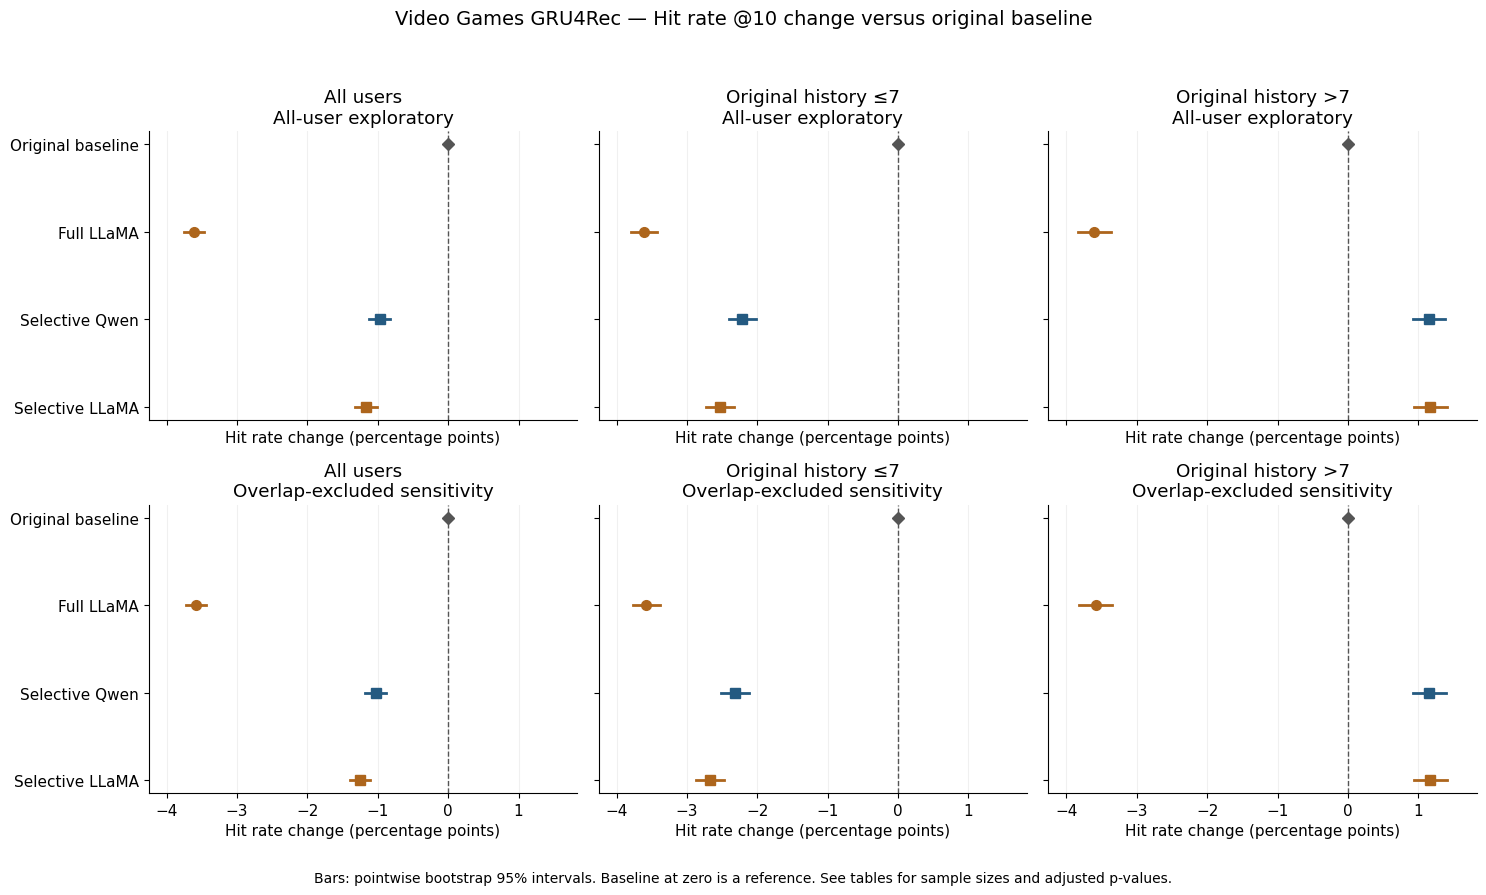

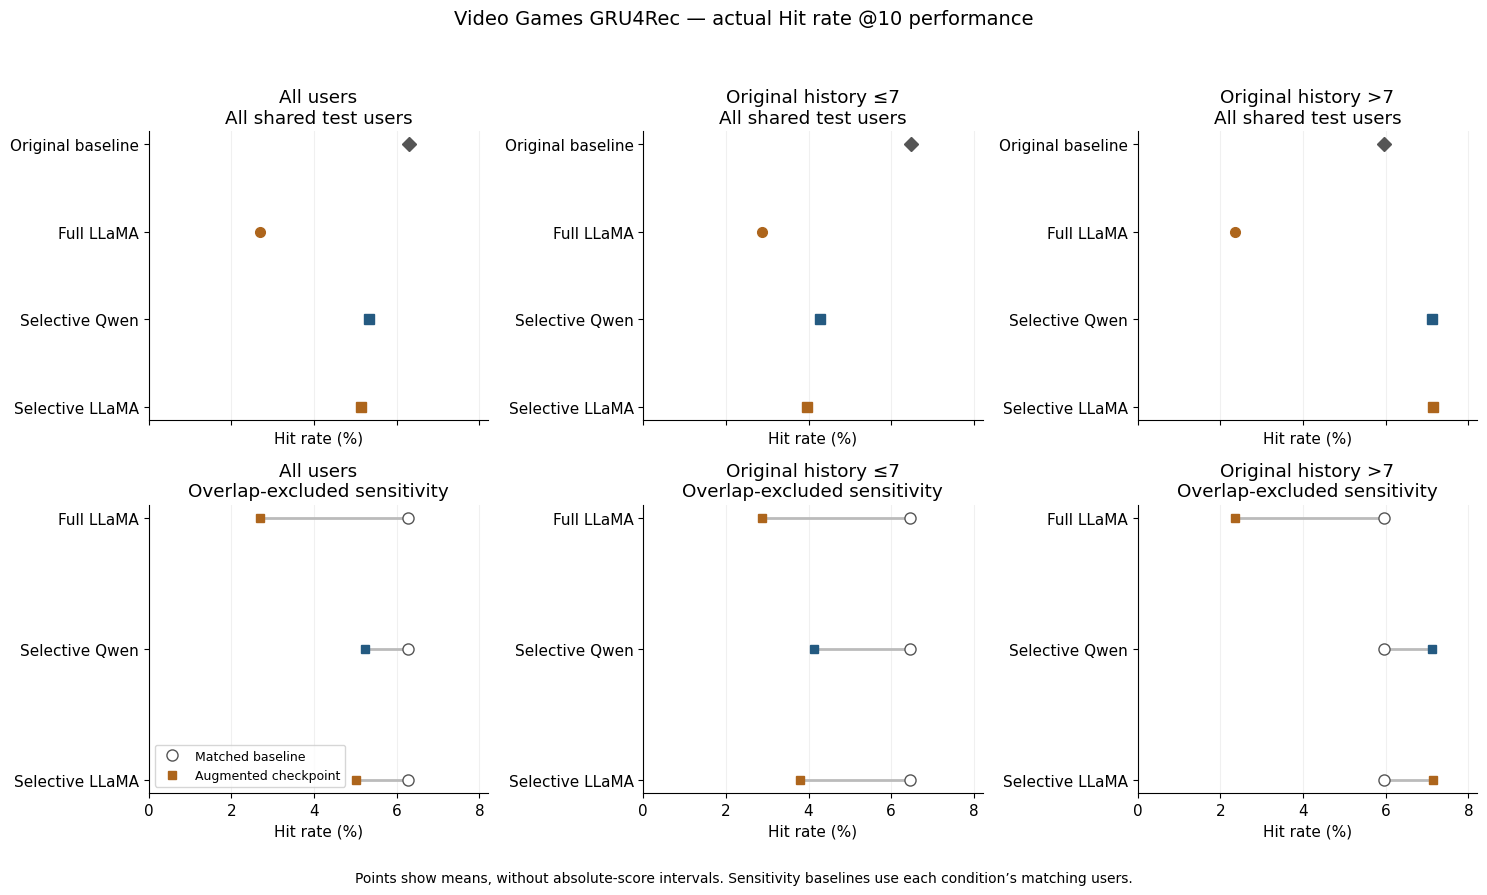

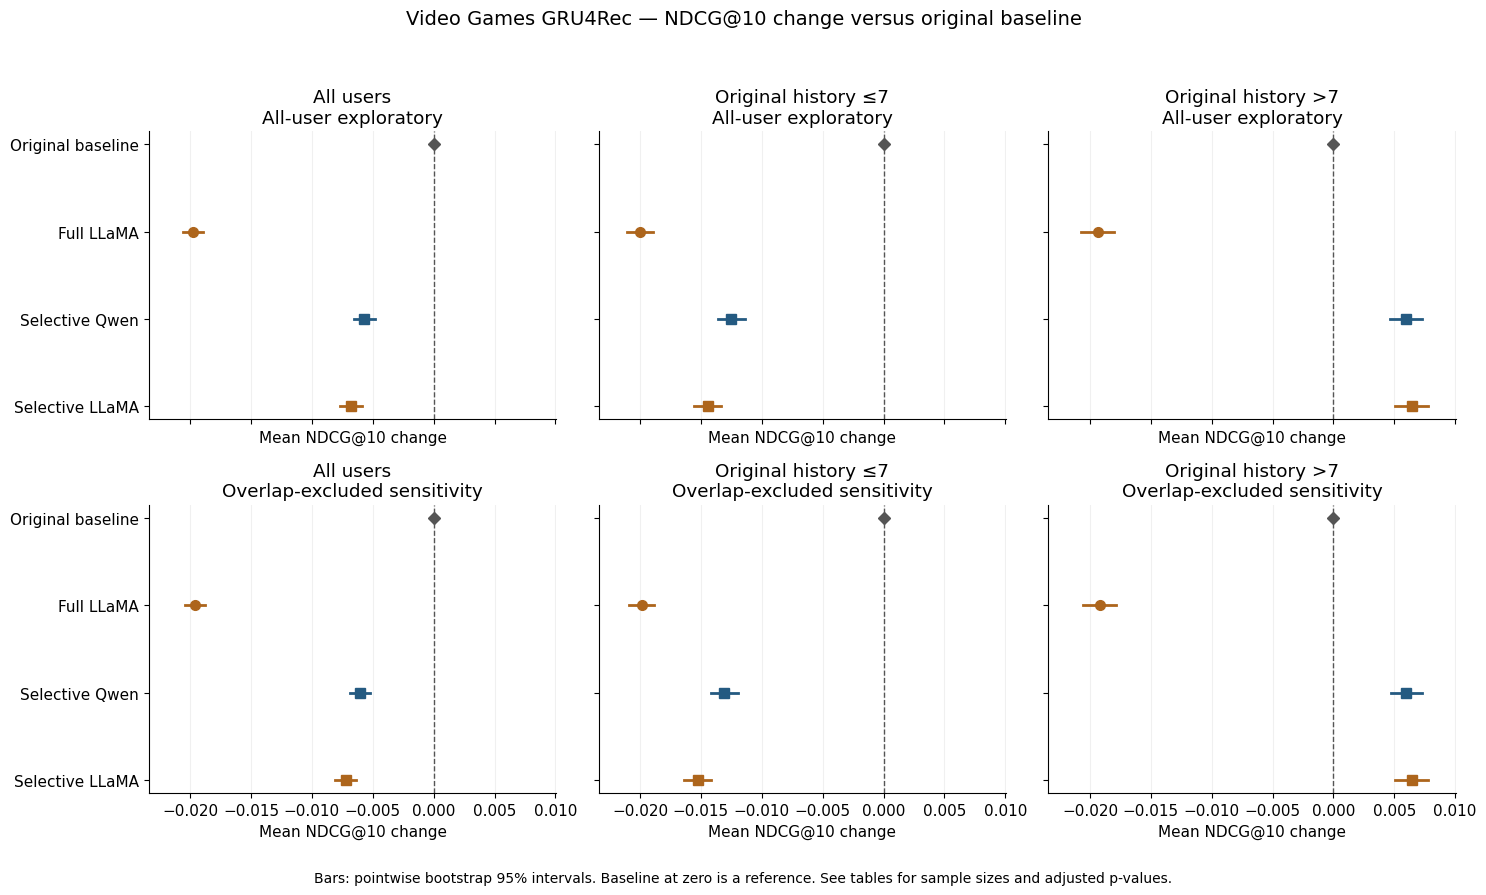

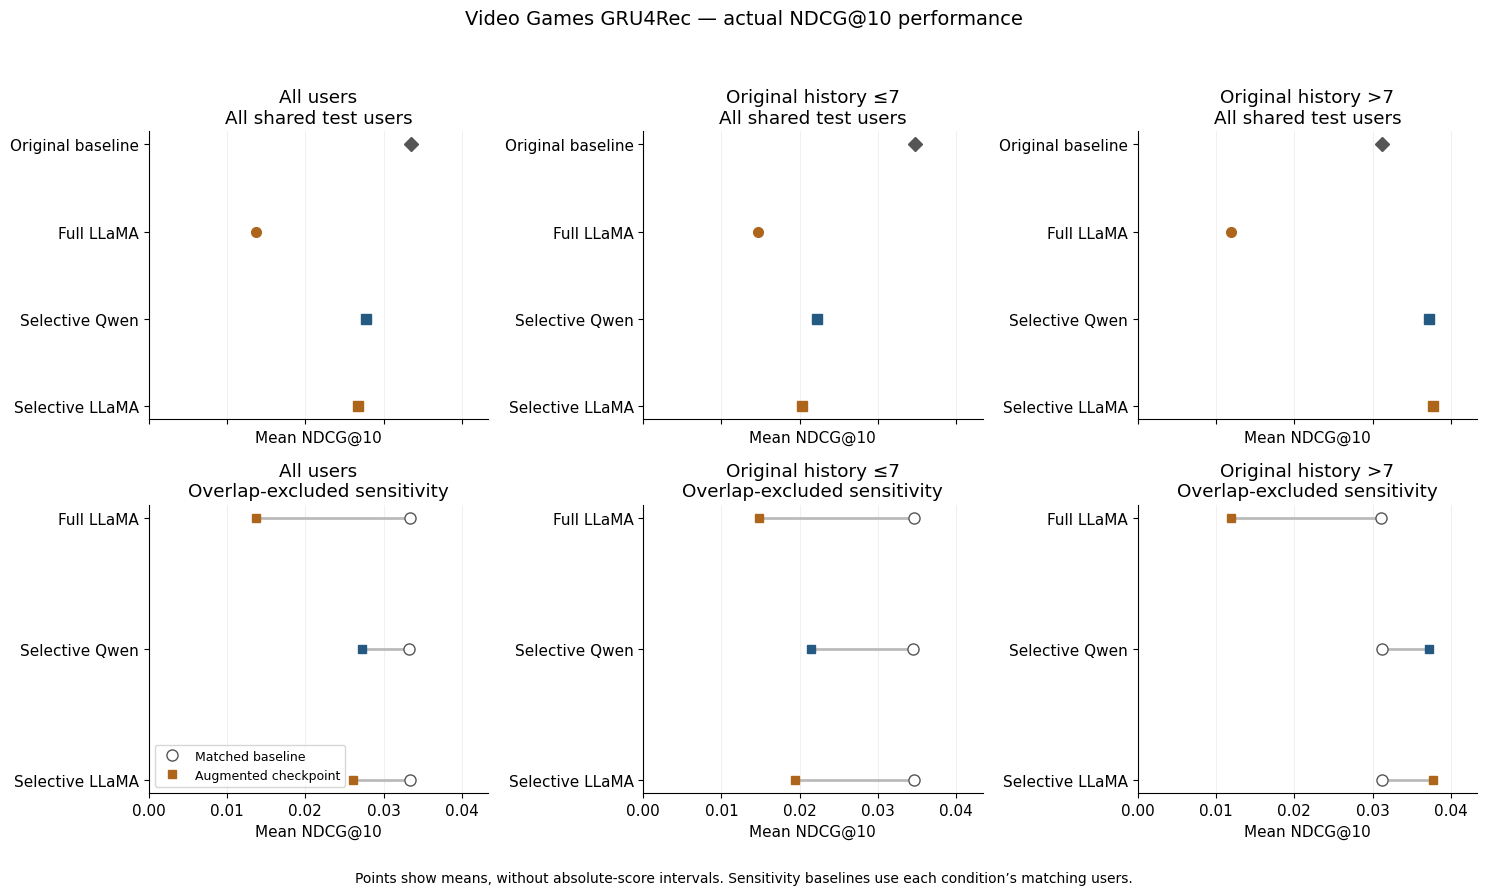

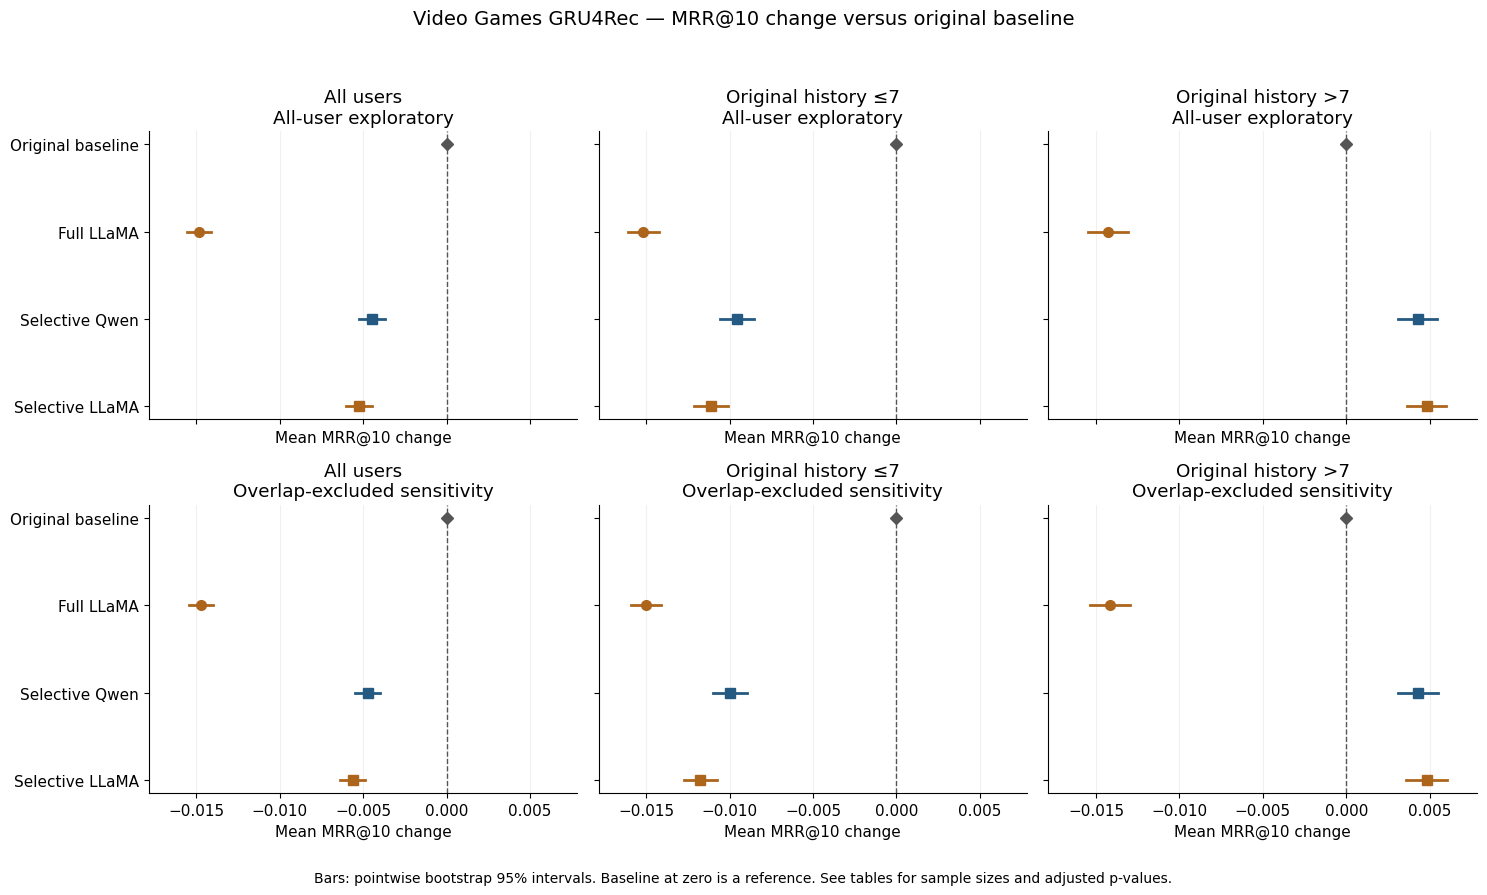

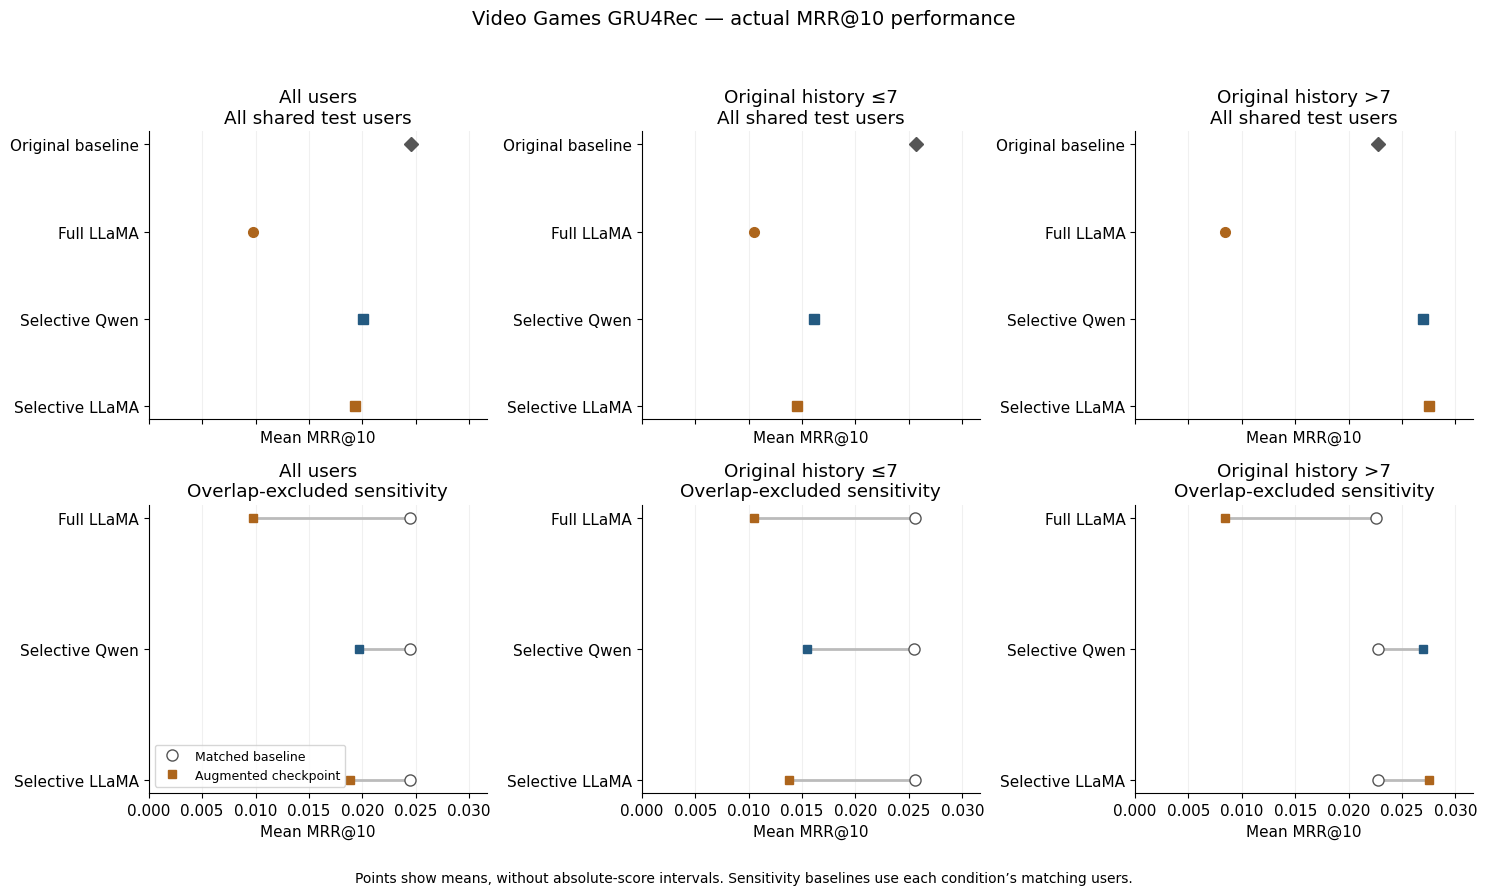

In [14]:
COLORS = {'full_qwen': '#245A81', 'selective_qwen': '#245A81', 'full_llama': '#AD651C', 'selective_llama': '#AD651C'}
BASELINE_COLOR = '#555555'

def save_and_show(fig, filename):
    fig.savefig(RUN_DIR / 'figures' / filename, dpi=180, bbox_inches='tight')
    plt.show()
    plt.close(fig)

def plot_metric_results(result_table, absolute_table):
    for metric in DISPLAY_METRICS:
        selected = result_table.loc[result_table.metric.eq(metric)]
        scale = 100. if metric == 'hit@10' else 1.
        low, high = selected.ci95_low.min() * scale, selected.ci95_high.max() * scale
        span = max(high - low, .1 if metric == 'hit@10' else .001)
        fig, axes = plt.subplots(2, 3, figsize=(15, 9), sharex=True, sharey=True)
        for r, population in enumerate(POPULATIONS):
            for axis, group in zip(axes[r], GROUPS):
                rows = selected.loc[selected.population.eq(population) & selected.group.eq(group)].set_index('condition')
                axis.plot(0, 0, marker='D', color=BASELINE_COLOR, markersize=6)
                for y, condition in enumerate(CONDITIONS, start=1):
                    row = rows.loc[condition]
                    axis.plot([row.ci95_low * scale, row.ci95_high * scale], [y, y], color=COLORS[condition], linewidth=2)
                    axis.plot(row.delta * scale, y, marker='o' if condition.startswith('full') else 's', color=COLORS[condition], markersize=7)
                axis.axvline(0, color=BASELINE_COLOR, linestyle='--', linewidth=1)
                axis.set_xlim(min(low, 0) - .08 * span, max(high, 0) + .08 * span)
                axis.set_yticks(range(len(CONDITIONS) + 1), ['Original baseline'] + [LABELS[c] for c in CONDITIONS])
                axis.set_title(GROUP_TITLES[group] + '\n' + ('All-user exploratory' if r == 0 else 'Overlap-excluded sensitivity'))
                axis.grid(axis='x', alpha=.18)
                axis.set_xlabel('Hit rate change (percentage points)' if metric == 'hit@10' else f'Mean {METRIC_TITLES[metric]} change')
        axes[0, 0].invert_yaxis()
        fig.suptitle('Video Games GRU4Rec — ' + METRIC_TITLES[metric] + ' change versus original baseline', fontsize=14)
        fig.text(.5, .01, 'Bars: pointwise bootstrap 95% intervals. Baseline at zero is a reference. See tables for sample sizes and adjusted p-values.', ha='center', fontsize=10)
        fig.tight_layout(rect=[0, .04, 1, .95])
        save_and_show(fig, f'{metric.replace("@", "_")}_changes.png')

        # Main absolute values: five standalone rows. Sensitivity: matched pairs.
        max_value = max(absolute_table[metric].max(), selected[['baseline_mean', 'augmented_mean']].max().max()) * scale
        fig, axes = plt.subplots(2, 3, figsize=(15, 9), sharex=True)
        for axis, group in zip(axes[0], GROUPS):
            rows = absolute_table.loc[absolute_table.group.eq(group)].set_index('condition')
            for y, condition in enumerate(['baseline'] + CONDITIONS):
                axis.plot(rows.loc[condition, metric] * scale, y, marker='D' if condition == 'baseline' else ('o' if condition.startswith('full') else 's'),
                          color=BASELINE_COLOR if condition == 'baseline' else COLORS[condition], markersize=7)
            axis.set_yticks(range(len(CONDITIONS) + 1), [LABELS[c] for c in ['baseline'] + CONDITIONS])
            axis.invert_yaxis()
            axis.set_title(GROUP_TITLES[group] + '\nAll shared test users')
        for axis, group in zip(axes[1], GROUPS):
            rows = selected.loc[selected.population.eq('overlap_excluded_sensitivity') & selected.group.eq(group)].set_index('condition')
            for y, condition in enumerate(CONDITIONS):
                row = rows.loc[condition]
                axis.plot([row.baseline_mean * scale, row.augmented_mean * scale], [y, y], color='#BBBBBB', linewidth=2)
                axis.plot(row.baseline_mean * scale, y, marker='o', markerfacecolor='white', markeredgecolor=BASELINE_COLOR, markersize=8,
                          linestyle='none', label='Matched baseline' if y == 0 else None)
                axis.plot(row.augmented_mean * scale, y, marker='s', color=COLORS[condition], markersize=6,
                          linestyle='none', label='Augmented checkpoint' if y == 0 else None)
            axis.set_yticks(range(len(CONDITIONS)), [LABELS[c] for c in CONDITIONS])
            axis.invert_yaxis()
            axis.set_title(GROUP_TITLES[group] + '\nOverlap-excluded sensitivity')
        axes[1, 0].legend(loc='best', fontsize=9)
        for axis in axes.flat:
            axis.set_xlim(0, max(max_value * 1.15, .1 if metric == 'hit@10' else .001))
            axis.set_xlabel('Hit rate (%)' if metric == 'hit@10' else 'Mean ' + METRIC_TITLES[metric])
            axis.grid(axis='x', alpha=.18)
        fig.suptitle('Video Games GRU4Rec — actual ' + METRIC_TITLES[metric] + ' performance', fontsize=14)
        fig.text(.5, .01, 'Points show means, without absolute-score intervals. Sensitivity baselines use each condition’s matching users.', ha='center', fontsize=10)
        fig.tight_layout(rect=[0, .04, 1, .95])
        save_and_show(fig, f'{metric.replace("@", "_")}_absolute_scores.png')

plot_metric_results(table, overview)

### 15. Hit gains/losses and sensitivity to overlaps
Hit-transition bars show the percentage of all users in each displayed cohort who gain or lose a hit; their denominators differ in sensitivity panels and appear in the transition table. The sparse-user sensitivity figure compares the two estimates and their pointwise intervals descriptively; it does not test whether excluding users caused a change. The audit chart counts each overlap user once, even if both validation and test items overlap.

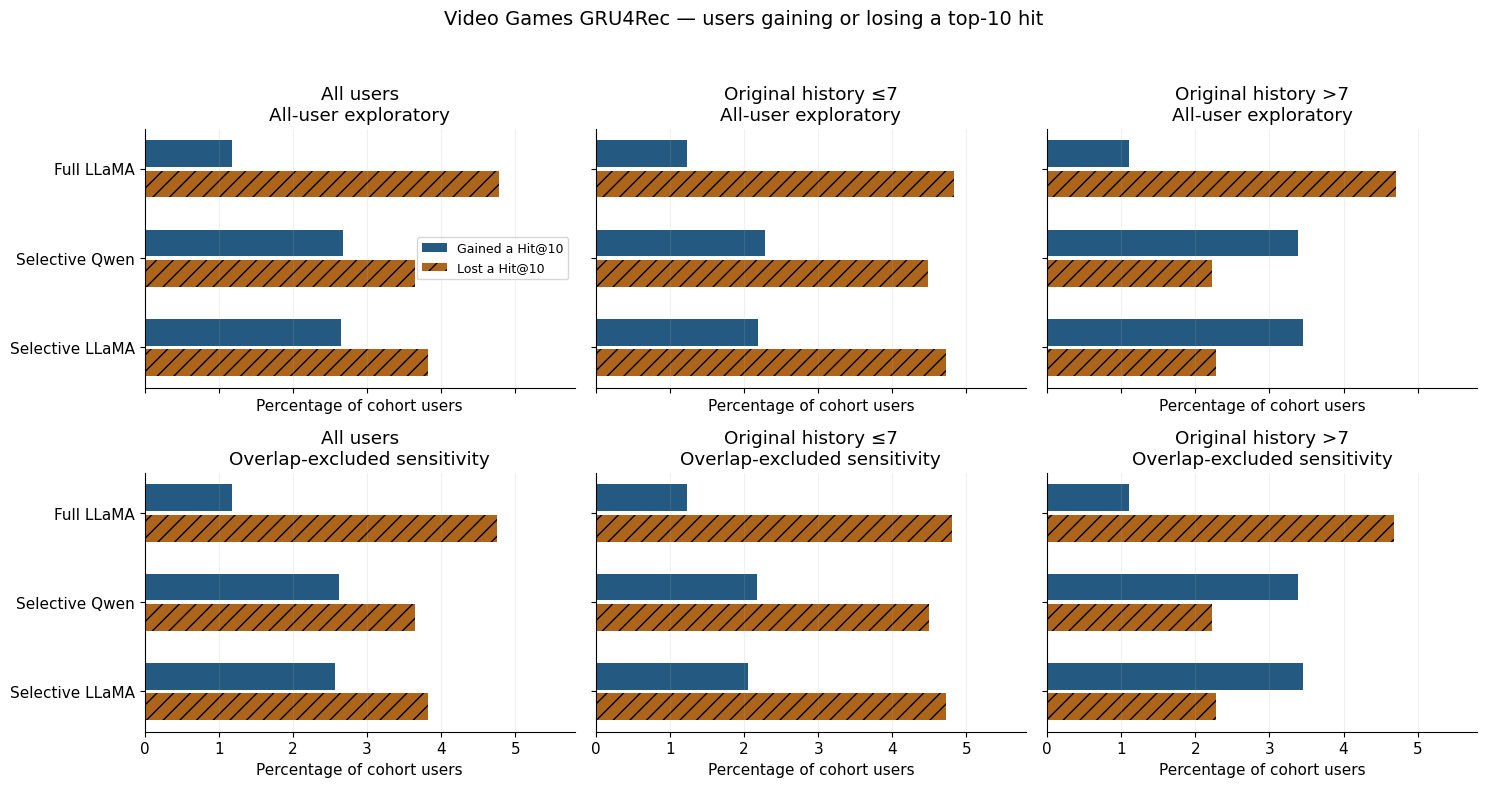

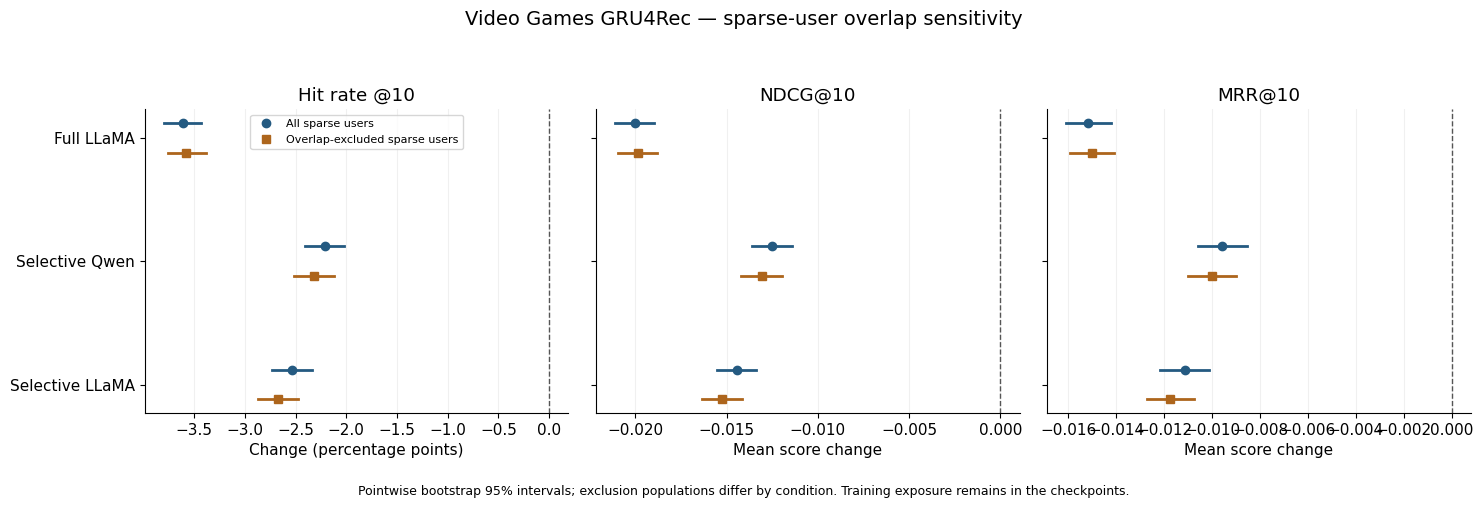

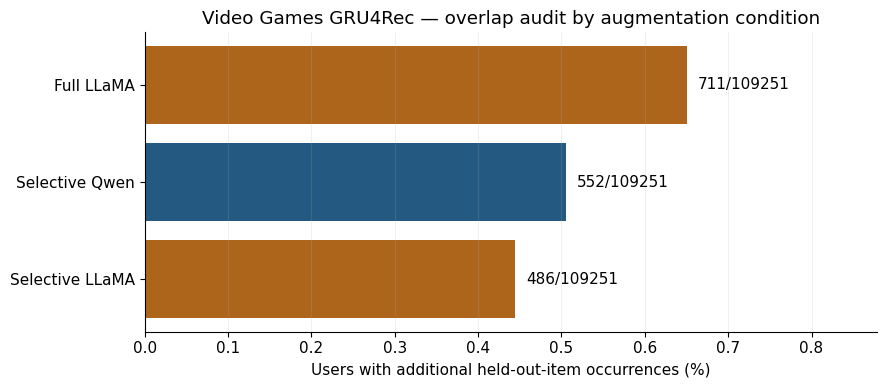

In [15]:
# User-level Hit gains and losses.
limit = max(transitions[['gained_hit_pct', 'lost_hit_pct']].max().max() * 1.2, .1)
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True, sharey=True)
for r, population in enumerate(POPULATIONS):
    for axis, group in zip(axes[r], GROUPS):
        rows = transitions.loc[transitions.population.eq(population) & transitions.group.eq(group)].set_index('condition').reindex(CONDITIONS)
        y = np.arange(len(CONDITIONS))
        axis.barh(y - .17, rows.gained_hit_pct, height=.3, color='#245A81', label='Gained a Hit@10')
        axis.barh(y + .17, rows.lost_hit_pct, height=.3, color='#AD651C', hatch='//', label='Lost a Hit@10')
        axis.set_yticks(y, [LABELS[c] for c in CONDITIONS])
        axis.set_title(GROUP_TITLES[group] + '\n' + ('All-user exploratory' if r == 0 else 'Overlap-excluded sensitivity'))
        axis.set_xlim(0, limit)
        axis.set_xlabel('Percentage of cohort users')
        axis.grid(axis='x', alpha=.18)
axes[0, 0].invert_yaxis()
axes[0, 0].legend(loc='best', fontsize=9)
fig.suptitle('Video Games GRU4Rec — users gaining or losing a top-10 hit', fontsize=14)
fig.tight_layout(rect=[0, 0, 1, .95])
save_and_show(fig, 'hit_gains_and_losses.png')

# Side-by-side sensitivity estimates for sparse users, all three metrics.
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)
for axis, metric in zip(axes, DISPLAY_METRICS):
    scale = 100. if metric == 'hit@10' else 1.
    for j, population in enumerate(POPULATIONS):
        rows = table.loc[table.metric.eq(metric) & table.group.eq('sparse') & table.population.eq(population)].set_index('condition')
        for y, condition in enumerate(CONDITIONS):
            row = rows.loc[condition]
            yy = y + (-.12 if j == 0 else .12)
            color = '#245A81' if j == 0 else '#AD651C'
            axis.plot([row.ci95_low * scale, row.ci95_high * scale], [yy, yy], color=color, linewidth=2)
            axis.plot(row.delta * scale, yy, marker='o' if j == 0 else 's', color=color, markersize=6,
                      linestyle='none', label=('All sparse users' if j == 0 else 'Overlap-excluded sparse users') if y == 0 else None)
    axis.axvline(0, color=BASELINE_COLOR, linestyle='--', linewidth=1)
    axis.set_title(METRIC_TITLES[metric])
    axis.set_xlabel('Change (percentage points)' if metric == 'hit@10' else 'Mean score change')
    axis.set_yticks(range(len(CONDITIONS)), [LABELS[c] for c in CONDITIONS])
    axis.grid(axis='x', alpha=.18)
axes[0].invert_yaxis()
axes[0].legend(loc='best', fontsize=8)
fig.suptitle('Video Games GRU4Rec — sparse-user overlap sensitivity', fontsize=14)
fig.text(.5, .01, 'Pointwise bootstrap 95% intervals; exclusion populations differ by condition. Training exposure remains in the checkpoints.', ha='center', fontsize=9)
fig.tight_layout(rect=[0, .05, 1, .93])
save_and_show(fig, 'sparse_overlap_sensitivity_all_metrics.png')

fig, axis = plt.subplots(figsize=(9, 4))
ordered_audits = audits.set_index('condition').reindex(CONDITIONS)
y = np.arange(len(CONDITIONS))
axis.barh(y, ordered_audits.overlap_pct, color=[COLORS[c] for c in CONDITIONS])
axis.set_yticks(y, [LABELS[c] for c in CONDITIONS])
axis.invert_yaxis()
axis.set_xlabel('Users with additional held-out-item occurrences (%)')
axis.set_title('Video Games GRU4Rec — overlap audit by augmentation condition')
maximum = max(float(ordered_audits.overlap_pct.max()), .1)
axis.set_xlim(0, maximum * 1.35)
for yy, row in enumerate(ordered_audits.itertuples()):
    axis.text(row.overlap_pct + .02 * maximum, yy, f'{row.any_overlap_users}/{row.users}', va='center')
axis.grid(axis='x', alpha=.18)
fig.tight_layout()
save_and_show(fig, 'holdout_overlap_audit.png')

## Checks and takeaways
### 12. Save the manifest and bounded interpretation
All results are exploratory analyses of existing checkpoints. Do not transfer significance conclusions from another recommender or dataset; compute them from these checkpoints. This cell summarizes only newly computed results.

In [16]:
environment = {p: package_metadata.version(p) for p in ['torch', 'recbole', 'numpy', 'pandas', 'scipy']}
manifest = {'scope': 'Video Games GRU4Rec verified available conditions', 'unavailable_conditions': UNAVAILABLE_CONDITIONS,
            'evaluation_protocol': 'Common real-item catalogue and shared users; separate native historical reproduction',
            'common_users': len(COMMON_USERS), 'common_items': len(COMMON_ITEMS), 'threshold': THRESHOLD,
            'k': K, 'seed': SEED, 'bootstrap_resamples': BOOTSTRAP_RESAMPLES,
            'difference_tests_per_population': 36, 'observed_difference_tests_per_population': len(CONDITIONS) * 3 * len(METRICS),
            'policy_tests_per_population': 18, 'hit_mcnemar_tests_per_population': 12,
            'derived_metrics': {'recall@10': 'hit@10', 'precision@10': 'hit@10 / 10'},
            'no_harm_margins': NO_HARM_MARGINS, 'margin_justifications': MARGIN_JUSTIFICATIONS,
            'environment': environment, 'inputs': provenance,
            'limitations': ['Checkpoint-conditional inference; no repeated training seeds',
                           'Different training batch sizes', 'Synthetic holdout-item overlaps',
                           'Sensitivity exclusions do not undo model training exposure',
                           'Pointwise intervals; adjusted p-values govern multiple-test decisions']}
(RUN_DIR / 'run_manifest.json').write_text(json.dumps(manifest, indent=2, default=str))
summary_lines = ['Video Games GRU4Rec full/selective augmentation comparisons',
                 'Delta = augmented minus baseline. All conclusions refer to these checkpoints.',
                 'Holm correction: 36 planned difference tests per population.', '']
for row in table.to_dict('records'):
    p = row['p_holm']
    conclusion = ('statistically detected increase' if row['delta'] > 0 else 'statistically detected decrease') if pd.notna(p) and p < .05 else 'difference not established under Holm correction'
    summary_lines.append(f"{row['condition']} | {row['population']} | {row['group']} | {row['metric']} | n={row['users']} | delta={row['delta']:.6f} | {conclusion}")
summary_lines += ['', 'Nonsignificance does not establish equivalence or no meaningful harm.',
                  'Full longer-history users received augmentation; selective longer-history users did not.',
                  'Overlap-excluded sensitivity is not a contamination-free retraining experiment.']
(RUN_DIR / 'analysis/interpretation.txt').write_text('\n'.join(summary_lines))
print('\n'.join(summary_lines))
print('\nAll outputs:', RUN_DIR)

Video Games GRU4Rec full/selective augmentation comparisons
Delta = augmented minus baseline. All conclusions refer to these checkpoints.
Holm correction: 36 planned difference tests per population.

full_llama | all_users_exploratory | all | ndcg@10 | n=109251 | delta=-0.019777 | statistically detected decrease
full_llama | all_users_exploratory | all | hit@10 | n=109251 | delta=-0.036082 | statistically detected decrease
full_llama | all_users_exploratory | all | mrr@10 | n=109251 | delta=-0.014838 | statistically detected decrease
full_llama | all_users_exploratory | sparse | ndcg@10 | n=69069 | delta=-0.020037 | statistically detected decrease
full_llama | all_users_exploratory | sparse | hit@10 | n=69069 | delta=-0.036094 | statistically detected decrease
full_llama | all_users_exploratory | sparse | mrr@10 | n=69069 | delta=-0.015168 | statistically detected decrease
full_llama | all_users_exploratory | longer_history | ndcg@10 | n=40182 | delta=-0.019330 | statistically detected

## Next steps
Share `analysis/absolute_performance.csv`, `analysis/group_results.csv`, `analysis/hit_transitions.csv`, `analysis/full_vs_selective.csv`, `analysis/cohort_effect_contrasts.csv` and `preparation/augmentation_audit.csv` for interpretation. Keep the new `run_manifest.json` and checkpoint-config audit with your results. To reuse this for another model/dataset, explicitly update checkpoint names, recorded results, expected augmentation policy and cohort rules; this notebook is restricted to the named Video Games recommender and does not silently extend to other models or Video Games.

For a controlled augmentation-only claim, use matched training settings and remove synthetic holdout-item overlaps before training. Existing-checkpoint sensitivity analyses cannot replace that experiment. Agree a meaningful no-harm margin with your supervisor before using the optional margin cell.